# Stage evaluation: how good is every section of the pipeline?

`Single_Image_Run.ipynb` answers "what score do we get and how long does it take". This notebook asks the question one level deeper: **which section loses the points, and how much?** It uses the same pipeline pieces, one photo at a time, but looks at what each stage hands to the next.

**"Found" means: a place within 4 sigma of the truth** (the +3 point band). The strict version, within 1 sigma (+10 points), is always shown next to it. Both numbers are in `FOUND_SIGMA` and `STRICT_SIGMA`.

| Stage | Question | What is measured |
|---|---|---|
| 1. Image processing | Is the photo usable, and does it look like the map where it truly is? | valid share and contrast of the north-up canvas; edge strength; the score of every map at the true place against the rest of the 5 km disc |
| 2. Coarse search | Is the target among the chosen peaks? | recall at K (target anywhere in the first K peaks), rank of the first right peak, does the global maximum of the score map lie at the target |
| 3. Semantic layer (DINO) | Does it help the first place, and does it keep the target when only M of K go on? | top-1 before and after (paired, with interval), recall at M of K, rank of the first right peak, how well the DINO score separates right from wrong places |
| 4. Fine matching | If the target is among the M, does the matcher find it? | inliers of the right candidate against the wrong ones, how often the right one has the most inliers, how often it has none, error after the shift correction |
| 5. Decision | Does it answer the right photos? | precision, answerable photos that were skipped, points lost to skipping and to wrong answers, bar sweep |
| 6. End to end | Where do the points go? | a funnel: all photos, target in K, target in M, right candidate chosen, answered, within 4 sigma, within 1 sigma |

**How it runs, in three passes.** Pass A (Part 3) renders each photo, computes the score maps, the K_MAX best peaks and the DINO scores once. Pass B (Part 4) runs the fine matcher on all K_MAX peaks of every photo once per matcher. Everything after that (the tables and the hyperparameter sweeps of K, M, DINO weight, answer bar, gamma, rescue rule) is calculated from the stored numbers, **without matching again**. Sweeping a hyperparameter therefore costs seconds.

**Read the sweeps with care.** They search many settings on the same 100 photos they are scored on, so the best row is optimistic. Trust a setting only if it also helps in both halves of the photos, and look for a flat region, not a single best row.

**Analysis of every hyperparameter.** Part 8 re-scores the stored results over one logical range per hyperparameter (K, M, DINO weight, answer bar, gamma, rescue rule, DINO layer on or off, and for LoFTR the confidence cut and the RANSAC distance): 8.4 one at a time, 8.5 in pairs. What changes the data itself (map, margin, coarse method, matcher, number of photos) is compared across runs in Part 10.

# Part 1 · Settings

In [1]:
import os, sys, math, time, gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "single_photo_pipeline.py").exists():
    ROOT = ROOT.parent                    # walk up to the repo folder
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)

# ------------------------------------------------------------------ settings: change here, run again
DATA = "official"           # "official" (d1 photos) or "nudt" (Changsha test photos)
NUDT_SPLIT = "test"         # DATA = "nudt" only: "test" (2350 photos), "valid" (1425), "train" (8115) or "all" (11890). For a whole-data-set run also set N_PHOTOS = 100000 (it is capped at what exists)
N_PHOTOS = 500              # photos loaded for the data set (spread over the flights)
N_EVAL = 100                # photos evaluated
FIRST_PHOTO = 0             # the first photo of the window (photos FIRST_PHOTO ... FIRST_PHOTO + N_EVAL - 1): use another window to test a setting on photos it was not tuned on
COARSE = "fused"            # the coarse method that goes on to the fine stage: "fused" or "edge_zncc". The other one is evaluated for stages 1 to 3 only
MATCHERS = ["loftr_minima"] # fine matchers to evaluate, e.g. ["roma_minima", "loftr_minima", "lightglue"]. The first one is the baseline in all tables
K_MAX = 100                 # peaks kept per photo and sent through the fine stage once (every K and M of the sweeps is taken from these)
FOUND_SIGMA = 4.0           # a place counts as found when it is within this many sigma of the truth
STRICT_SIGMA = 1.0          # the strict version, shown next to it

# the baseline setting for the stage tables (the sweeps in Part 8 vary these)
USE_SEMANTIC_LAYER = True   # DINO re-orders the K shortlist and the best M go to the fine stage; False = the first M of the coarse order
K_BASE = 100                # K: places the coarse search returns
M_BASE = 25                 # M <= K: places that count as sent to the fine stage
WEIGHT_BASE = 100.0         # DINO weight in the re-ordering: z(coarse) + WEIGHT * z(DINO); 100 = DINO decides inside the K, 0 = coarse order
MIN_INLIERS = 8             # answer bar: answer when the chosen place has at least this many inliers
GAMMA = 1.0                 # choose by  inliers + GAMMA * (DINO z-score);  0 = inliers only
RESCUE_INLIERS = None       # e.g. 6: also answer with this many inliers (instead of MIN_INLIERS) ...
RESCUE_Z = None             # ... when the DINO z-score of the chosen place is at least this (e.g. 2.0)
RANSAC_PIXELS = None        # inlier distance in pixels (None = 3.0 from settings)
MATCHER_CONFIDENCE = 0.3    # LoFTR only

# the values the sweeps in Part 8 go through: one logical range per hyperparameter (the baseline above should lie inside it)
K_LIST = [5, 10, 25, 50, 100, 150, 200]          # places the coarse search returns (values above K_MAX are skipped)
M_LIST = [1, 3, 5, 10, 15, 25, 50]               # places sent to the fine stage (1 = trust the first place; M > K is skipped)
WEIGHT_LIST = [0.0, 0.3, 1.0, 3.0, 10.0, 100.0]  # DINO weight in the re-ordering: 0 = coarse order ... 100 = DINO decides
BAR_MIN = 4                                      # the answer bar is swept from BAR_MIN to BAR_MAX in steps of BAR_STEP (inliers the chosen place needs)
BAR_MAX = 16
BAR_STEP = 3
BAR_LOW = [1, 2, 3]                              # extra low bars (strategy S1 of Part 11); [] sweeps only BAR_MIN to BAR_MAX
BAR_LIST = sorted(set(BAR_LOW + list(range(BAR_MIN, BAR_MAX + 1, BAR_STEP))))      # 1, 2, 3, 4, 7, 10, 13, 16
GAMMA_LIST = [0.0, 0.25, 0.5, 1.0, 2.0, 4.0]     # weight of the DINO z-score when choosing the candidate (0 = inliers only)
RESCUE_LIST = [None, (4, 2.0), (6, 2.0), (8, 2.5), (0, 2.5), (0, 3.0), (0, 3.5)]   # (inliers, DINO z): also answer with fewer inliers when DINO is sure; (0, z) answers the unrefined first place that has no inliers at all
CONF_LIST = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]  # LoFTR only: confidence cut of a match (LoFTR drops matches below 0.2 by itself)
RANSAC_LIST = [1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0]    # LoFTR only: inlier distance in pixels of the 224 px canvas
# the last two are re-fitted from the stored matches of pass B (no new matching). What changes the data itself (MAP, MAP_MARGIN_M, COARSE, MATCHERS, N_EVAL)
# needs a new run of the notebook: every run is added to tests/Stage_Evaluation/runs_summary.csv and compared in Part 10.

N_SAMPLES = 4               # sample figures per kind of failure (Part 9)
SEED = 450
plt.rcParams["figure.dpi"] = 90

assert FIRST_PHOTO >= 0, "FIRST_PHOTO must be 0 or more"
assert FOUND_SIGMA > STRICT_SIGMA > 0, "need FOUND_SIGMA > STRICT_SIGMA > 0"
assert len(MATCHERS) >= 1, "give at least one matcher"
assert K_MAX >= K_BASE, "K_MAX must be at least K_BASE"
K_LIST = [k for k in K_LIST if k <= K_MAX]
assert 1 <= M_BASE <= K_BASE, "need 1 <= M_BASE <= K_BASE"
assert (RESCUE_INLIERS is None) == (RESCUE_Z is None), "give RESCUE_INLIERS and RESCUE_Z together"
assert 1 <= BAR_MIN <= BAR_MAX and BAR_STEP >= 1, "need 1 <= BAR_MIN <= BAR_MAX and BAR_STEP >= 1"
assert all(0.2 <= v < 1 for v in CONF_LIST) and all(v > 0 for v in RANSAC_LIST), "CONF_LIST needs values in 0.2..1 and RANSAC_LIST values above 0"


# Part 2 · Set up once

The same pieces as `single_photo_pipeline.py`: photos and camera, the map at all zoom levels, the feature families, the trained fusion model, the DINO network and the first matcher. Here the pipeline object is used as a **toolbox** (its parts are called one by one), not as a single call, because we want to see what every stage produced.

In [ ]:
from single_photo_pipeline import SinglePhotoPipeline      # first import: it saves the development-set settings before NUDT changes them
import cv2
import torch
from header import settings
from header.settings import DEVICE
from train import config
from src.header.scoring import points_for_error, final_score
from image_processing.geometry import render_query
from image_processing.map_levels import level_for_height, map_piece
from image_processing.edge_features import query_edge_features
from image_processing.thermal import load_thermal_frame, normalise_frame
from train.coarse_methods.inputs import make_inputs
from train.coarse_methods.single_map import make_single_map_method
from semantic_rerank.dino_rerank import shortlist_peaks, dino_candidate_scores, rerank_peaks
from semantic_rerank.decision import shortlist_z, choose_candidate, decide_with_dino
from fine_matching.second_stage_any import run_fine_stage

pipeline = SinglePhotoPipeline(DATA, COARSE, semantic_layer=True, semantic_decision=True, k_peaks=K_MAX, m_fine=K_MAX,
                               matcher=MATCHERS[0], min_inliers=MIN_INLIERS, ransac_pixels=RANSAC_PIXELS,
                               matcher_confidence=MATCHER_CONFIDENCE, nudt_split=NUDT_SPLIT)
start = time.time()
pipeline.setup(N_PHOTOS, SEED)
print("setup done in %.1f s" % (time.time() - start))
for line in pipeline.describe():
    print(line)

test_set = pipeline.test_set
camera = pipeline.camera
level_images = pipeline.level_images

# the coarse methods that are evaluated: the fused one (or edge_zncc if there is no saved fusion model) and edge_zncc alone
PRIMARY = pipeline.coarse_name
METHODS = {"edge_zncc": make_single_map_method("edge_zncc")}
if PRIMARY != "edge_zncc":
    METHODS[PRIMARY] = pipeline.coarse_method
print("coarse methods evaluated:", list(METHODS), "| the fine stage runs on:", PRIMARY)
print("maps inside the fusion:", pipeline.names)

# Part 3 · Pass A: photo, score maps, peaks and DINO scores (no matcher yet)

For every photo, without the matcher:

1. **Render** the north-up canvas. Keep its valid share, contrast and edge strength (stage 1).
2. **Score maps.** For each map in the fusion and for each coarse method, find where in the 5 km disc the best score lies relative to the truth: `truth_stats` gives the global maximum's distance from the truth (in sigma), and the best score within 4 sigma of the truth against the rest of the disc (a z-score and a margin).
3. **Peaks.** For each coarse method, the K_MAX best peaks, their error in sigma, and the DINO scores of those places.

The truth is used only to judge. Nothing the pipeline does depends on it.

In [ ]:
def errors_in_sigma(peaks, index):
    assert peaks.ndim == 2 and peaks.shape[1] >= 3, "peaks must be (n, >= 3)"
    truth = test_set.truths[index]
    sigma = test_set.sigmas[index]
    errors = np.full(len(peaks), 1e9)
    for k in range(len(peaks)):
        if peaks[k, 1] < 1e8:
            errors[k] = math.hypot(peaks[k, 1] - truth[0], peaks[k, 2] - truth[1]) / sigma
    return errors


def truth_stats(score_map, usable, geometry, truth, sigma):
    # What does this score map say about the true place?
    #   argmax_err  distance (in sigma) of the highest score of the whole disc from the truth
    #   near_z      z-score (over the disc) of the best score within FOUND_SIGMA of the truth
    #   margin      best score near the truth minus best score elsewhere (positive = the truth area wins)
    assert score_map.shape == usable.shape == geometry["inside"].shape, "score map, usable mask and grid must have the same shape"
    assert sigma > 0, "sigma must be positive"
    empty = dict(argmax_err=np.nan, near_z=np.nan, margin=np.nan)
    if int(usable.sum()) < 10:
        return empty
    x_m = geometry["x_m"]
    y_m = geometry["y_m"]
    distance_sq = (x_m[None, :] - truth[0]) ** 2 + (y_m[:, None] - truth[1]) ** 2
    values = score_map[usable]
    mean = float(values.mean())
    spread = float(values.std()) + 1e-9

    masked = score_map.clone()
    masked[~usable] = -1e9
    best_flat = int(masked.reshape(-1).argmax())
    row = best_flat // score_map.shape[1]
    col = best_flat % score_map.shape[1]
    argmax_err = math.hypot(float(x_m[col]) - truth[0], float(y_m[row]) - truth[1]) / sigma

    near = usable & (distance_sq <= (FOUND_SIGMA * sigma) ** 2)
    far = usable & (distance_sq > (FOUND_SIGMA * sigma) ** 2)
    if int(near.sum()) == 0 or int(far.sum()) == 0:
        return dict(argmax_err=argmax_err, near_z=np.nan, margin=np.nan)
    near_best = float(masked[near].max())
    far_best = float(masked[far].max())
    return dict(argmax_err=argmax_err, near_z=(near_best - mean) / spread, margin=near_best - far_best)

In [ ]:
records = []
failures = []
assert FIRST_PHOTO < len(test_set.items), "FIRST_PHOTO %d is beyond the %d photos" % (FIRST_PHOTO, len(test_set.items))
count = min(N_EVAL, len(test_set.items) - FIRST_PHOTO)
start = time.time()
for index in range(FIRST_PHOTO, FIRST_PHOTO + count):
    try:
        item = test_set.items[index]
        truth = test_set.truths[index]
        sigma = test_set.sigmas[index]
        cv2.setRNGSeed(settings.SEED)
        level = level_for_height(item["rel_height"], camera)
        canvas, valid = render_query(item, camera, level)
        assert valid.any(), "the canvas has no valid pixel"

        query_features, query_cells = query_edge_features(canvas, valid)
        cells_ok = np.asarray(query_cells) > 0
        edge_strength = 0.0
        if cells_ok.any():
            edge_strength = float(query_features.sum(axis=0)[cells_ok].mean())

        inputs = make_inputs(canvas, valid, level, test_set.priors[index], pipeline.families, pipeline.names)
        geometry = inputs["geometry"]
        record = dict(index=index, height=item["rel_height"], level=level, truth=truth, sigma=sigma,
                      canvas=canvas, valid=valid, valid_frac=float(valid.mean()), contrast=float(canvas[valid].std()),
                      edge_strength=edge_strength, maps={}, methods={})

        for name in pipeline.names:
            raw = inputs["maps"][name]
            usable = inputs["usable"] & (raw > -1)
            record["maps"][name] = truth_stats(raw, usable, geometry, truth, sigma)

        for method_name, method in METHODS.items():
            score_map = method(inputs)
            usable = geometry["inside"] & (score_map > -1)
            stats = truth_stats(score_map, usable, geometry, truth, sigma)
            short = shortlist_peaks(score_map, geometry, K_MAX)
            pooled, dense = dino_candidate_scores(pipeline.encoder, canvas, valid, level_images, level, short)
            record["methods"][method_name] = dict(stats=stats, short=short, dense=dense, pooled=pooled, err=errors_in_sigma(short, index))
        records.append(record)
        del inputs
    except Exception as error:
        failures.append(dict(photo=index, error="%s: %s" % (type(error).__name__, str(error)[:120])))
        print("photo %d failed: %s: %s" % (index, type(error).__name__, str(error)[:120]))
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    if (index - FIRST_PHOTO + 1) % 20 == 0:
        print("pass A: photo %d/%d, %.0f s" % (index - FIRST_PHOTO + 1, count, time.time() - start))

record_by_index = {record["index"]: record for record in records}
print("pass A done: %d photos in %.0f s (%d failed)" % (len(records), time.time() - start, len(failures)))
assert len(records) > 0, "no photo went through pass A"

pass A: photo 20/100, 77 s
photo 39 failed: OutOfMemoryError: CUDA out of memory. Tried to allocate 144.00 MiB. GPU 0 has a total capacity of 5.66 GiB of which 87.00 MiB is free. Pro
pass A: photo 40/100, 142 s
photo 41 failed: OutOfMemoryError: CUDA out of memory. Tried to allocate 144.00 MiB. GPU 0 has a total capacity of 5.66 GiB of which 86.56 MiB is free. Pro
photo 42 failed: OutOfMemoryError: CUDA out of memory. Tried to allocate 290.00 MiB. GPU 0 has a total capacity of 5.66 GiB of which 236.56 MiB is free. Pr
photo 45 failed: OutOfMemoryError: CUDA out of memory. Tried to allocate 290.00 MiB. GPU 0 has a total capacity of 5.66 GiB of which 237.00 MiB is free. Pr
photo 47 failed: OutOfMemoryError: CUDA out of memory. Tried to allocate 144.00 MiB. GPU 0 has a total capacity of 5.66 GiB of which 85.00 MiB is free. Pro
photo 50 failed: OutOfMemoryError: CUDA out of memory. Tried to allocate 144.00 MiB. GPU 0 has a total capacity of 5.66 GiB of which 87.00 MiB is free. Pro
photo 51 

# Part 4 · Pass B: the fine matcher on every peak, once per matcher

The matcher runs on all K_MAX peaks of the **primary coarse method**, in the order the coarse search gave them. Inliers and shifts are stored per peak. Because every candidate is judged on its own, any later choice of K, M, DINO weight or answer bar only picks rows out of these numbers. For several matchers the models are loaded one after the other, so only one is in the GPU at a time.

For `loftr_minima` the raw matches of every candidate (positions and confidence) are kept as well, so Part 8.4 can change the confidence cut and the RANSAC distance without running the network again.

In [ ]:
def load_fine_matcher(name):
    assert name in ("lightglue", "loftr_minima", "roma_minima"), "unknown matcher %r" % (name,)
    checkpoints = config.find_nudt_dir() / "checkpoint"
    if name == "loftr_minima":
        from fine_matching.loftr_matcher import load_loftr_matcher
        return load_loftr_matcher(checkpoints / "MINIMA" / "minima_loftr.ckpt", MATCHER_CONFIDENCE)
    if name == "roma_minima":
        from fine_matching.roma_matcher import load_roma_matcher
        return load_roma_matcher(checkpoints / "MINIMA" / "minima_roma.pth", checkpoints / "RoMa" / "dinov2_vitl14_pretrain.pth")
    from fine_matching.matcher import load_matcher
    settings.MINIMA_FILE = checkpoints / "MINIMA" / "minima_lightglue.pth"
    return load_matcher()


from fine_matching.loftr_matcher import candidate_matches, stage2_from_matches

fine = {}
fine_seconds = {}
raw_matches = {}      # LoFTR only: the raw matches of every candidate, so that the confidence cut and the RANSAC distance can be swept without the network
for name in MATCHERS:
    if name == MATCHERS[0]:
        matcher = pipeline.matcher
    else:
        matcher = load_fine_matcher(name)
    stored = {}
    start = time.time()
    for position, record in enumerate(records):
        short = record["methods"][PRIMARY]["short"]
        if name == "loftr_minima":
            cv2.setRNGSeed(settings.SEED)
            kept = candidate_matches(matcher, record["canvas"], record["valid"], record["level"], short, level_images)
            raw_matches.setdefault(name, {})[record["index"]] = kept
            stage2 = stage2_from_matches(kept, record["level"], matcher.min_confidence)
        else:
            stage2 = run_fine_stage(matcher, record["canvas"], record["valid"], record["level"], short, level_images)
        assert len(stage2["inliers"]) == len(short), "the fine stage must return one inlier count per peak"
        stored[record["index"]] = dict(inliers=np.asarray(stage2["inliers"], dtype=float), shifts=np.asarray(stage2["shifts"], dtype=float))
        if (position + 1) % 20 == 0:
            print("pass B (%s): photo %d/%d, %.0f s" % (name, position + 1, len(records), time.time() - start))
    fine[name] = stored
    fine_seconds[name] = time.time() - start
    print("pass B (%s) done in %.0f s: %.2f s per photo for %d candidates" % (name, fine_seconds[name], fine_seconds[name] / len(records), K_MAX))
    if name != MATCHERS[0]:
        del matcher
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()

pass B (loftr_minima): photo 20/66, 174 s
pass B (loftr_minima): photo 40/66, 347 s
pass B (loftr_minima): photo 60/66, 468 s
pass B (loftr_minima) done in 489 s: 7.41 s per photo for 100 candidates


# Part 5 · Scoring tools (no GPU, no matcher)

Everything below works on the stored numbers.

* `ordered_errors` : for a setting (K, M, layer, weight) the order in which the peaks go to the fine stage, and the error of each. With the layer on this is the same re-ordering as `semantic_layer` (`rerank_peaks` over the first K peaks); with the layer off it is the first M of the coarse order. The position in the shortlist is carried in column 3 of a copy of the peaks, because `rerank_peaks` does not use that column.
* `answer_for` : the answer for one photo under one setting (choose the candidate, decide, score), the same rules as `single_photo_pipeline.py`.
* `evaluate` : `answer_for` for every photo, as a table.
* `summarise` : one line of numbers for a table of settings.

In [ ]:
def ordered_errors(record, method_name, K, M, layer, weight):
    assert 1 <= M <= K <= K_MAX, "need 1 <= M <= K <= K_MAX, got M=%s K=%s" % (M, K)
    assert weight >= 0, "weight must be >= 0"
    data = record["methods"][method_name]
    if not layer:
        order = np.arange(M)
    else:
        sub = data["short"][:K].copy()
        sub[:, 3] = np.arange(K)                 # column 3 carries the position in the shortlist
        order = rerank_peaks(sub, data["dense"][:K], weight, keep=M)[:, 3].astype(int)
    return order, data["err"][order]


def answer_for(record, fine_one, cfg):
    assert set(cfg) >= {"K", "M", "layer", "weight", "gamma", "rescue", "bar"}, "cfg needs K, M, layer, weight, gamma, rescue, bar"
    data = record["methods"][PRIMARY]
    order, errors = ordered_errors(record, PRIMARY, cfg["K"], cfg["M"], cfg["layer"], cfg["weight"])
    peaks = data["short"][order]
    z_short = shortlist_z(data["dense"][:cfg["K"]]) if cfg["layer"] else np.zeros(cfg["K"])
    z = z_short[order]
    stage2 = dict(inliers=fine_one["inliers"][order], shifts=fine_one["shifts"][order])
    gamma = cfg["gamma"] if cfg["layer"] else 0.0
    rescue = cfg["rescue"] if cfg["layer"] else None
    x, y, inliers, chosen, z_chosen = choose_candidate(peaks, stage2, z, gamma)
    if rescue is None:
        answered = decide_with_dino(inliers, z_chosen, min_inliers=cfg["bar"])
    else:
        answered = decide_with_dino(inliers, z_chosen, rescue[0], rescue[1], min_inliers=cfg["bar"])
    truth = record["truth"]
    error_m = math.hypot(x - truth[0], y - truth[1])
    earned = points_for_error(error_m, record["height"], camera.fx)
    all_errors = data["err"][:cfg["K"]]
    row = dict(photo=record["index"], in_K=bool((all_errors <= FOUND_SIGMA).any()), in_M=bool((errors <= FOUND_SIGMA).any()),
               in_M_strict=bool((errors <= STRICT_SIGMA).any()), top1_ok=bool(errors[0] <= FOUND_SIGMA),
               chosen_right=bool(errors[chosen] <= FOUND_SIGMA), answered=bool(answered), inliers=float(inliers),
               z_chosen=float(z_chosen), err_sigma=error_m / record["sigma"], would_earn=earned,
               points=earned if answered else 0,
               chosen_rank=int(order[chosen]), top_first=bool(chosen == 0),               # position of the chosen place in the coarse order; was it the first place after the DINO order?
               dx_m=float(x - truth[0]), dy_m=float(y - truth[1]), err_m=error_m, height=float(record["height"]))   # signed east / north error, for the bias analysis (S7)
    details = dict(order=order, errors=errors, chosen=chosen, x=x, y=y)
    return row, details


def evaluate(cfg, matcher_name):
    assert matcher_name in fine, "matcher %r was not run in pass B" % (matcher_name,)
    rows = []
    for record in records:
        row, details = answer_for(record, fine[matcher_name][record["index"]], cfg)
        rows.append(row)
    return pd.DataFrame(rows)


def summarise(table):
    assert len(table) > 1, "need at least two photos"
    half = len(table) // 2
    answered = table["answered"]
    answered_ok = answered & (table["err_sigma"] <= FOUND_SIGMA)
    result = {}
    result["score (/60)"] = final_score(list(table["points"]))
    result["first half"] = final_score(list(table["points"][:half]))
    result["second half"] = final_score(list(table["points"][half:]))
    result["answered"] = answered.mean()
    result["target in K"] = table["in_K"].mean()
    result["target in M"] = table["in_M"].mean()
    result["top-1 ok"] = table["top1_ok"].mean()
    if table["in_M"].any():
        result["right chosen | target in M"] = table["chosen_right"][table["in_M"]].mean()
    else:
        result["right chosen | target in M"] = np.nan
    result["answered and ok"] = answered_ok.mean()
    result["wrong answers"] = int((table["points"] < 0).sum())
    result["right but skipped"] = int(((~answered) & (table["err_sigma"] <= FOUND_SIGMA)).sum())
    return result


BASE = dict(K=K_BASE, M=M_BASE, layer=USE_SEMANTIC_LAYER, weight=WEIGHT_BASE, gamma=GAMMA,
            rescue=None if RESCUE_INLIERS is None else (RESCUE_INLIERS, RESCUE_Z), bar=MIN_INLIERS)
base = {name: evaluate(BASE, name) for name in MATCHERS}
print("baseline setting:", BASE)
display(pd.DataFrame({name: summarise(base[name]) for name in MATCHERS}).T.round(3))

baseline setting: {'K': 100, 'M': 25, 'layer': True, 'weight': 100.0, 'gamma': 1.0, 'rescue': None, 'bar': 8}


,answered,answered and ok,first half,right but skipped,right chosen | target in M,score (/60),second half,target in K,target in M,top-1 ok,wrong answers
loftr_minima,0.742,0.742,37.455,9.0,0.983,43.455,49.455,0.894,0.894,0.848,0.0


# Part 6 · The stages one by one

## 6.1 Stage 1 · Image processing

Two questions: is the canvas a usable picture (valid share, contrast, edge strength), and does it look like the map **where it truly is**? The second one is measured on the score maps: if the true place does not stand out in a map, no search on top of that map can find it. For each map:

* **max at target (4σ / 1σ)**: the highest score of the whole disc lies within 4 (1) sigma of the truth. This is the strongest test: the map alone would give the right answer.
* **z near truth**: how many standard deviations above the disc's mean the best score near the truth is. Above 3 means the truth area is clearly visible in the map.
* **margin > 0**: the truth area holds a higher score than everything else.

,mean,min,25%,50%,75%,max
height,246.067,100.100,149.625,279.900,300.600,350.700
level,5.424,3.000,4.000,6.000,6.000,7.000
valid_frac,0.777,0.638,0.725,0.766,0.853,0.910
contrast,0.190,0.163,0.179,0.189,0.202,0.225
edge_strength,1.027,0.938,1.015,1.023,1.046,1.076
near_z (fused),3.762,1.882,2.833,3.854,4.317,6.101


,map,max at target (4 sigma),max at target (1 sigma),median z near truth,z near truth > 3,margin > 0
0,edge_zncc,0.803,0.530,9.365,1.000,0.803
1,edge_cosine,0.621,0.364,2.709,0.409,0.621
2,edge_mag,0.242,0.167,2.749,0.455,0.242
3,edge_zncc_w,0.803,0.515,8.634,1.000,0.803
4,mind_zncc,0.803,0.530,9.265,1.000,0.803
5,learned_zncc,0.773,0.485,6.497,0.970,0.773
6,fused,0.818,0.545,3.854,0.712,0.818


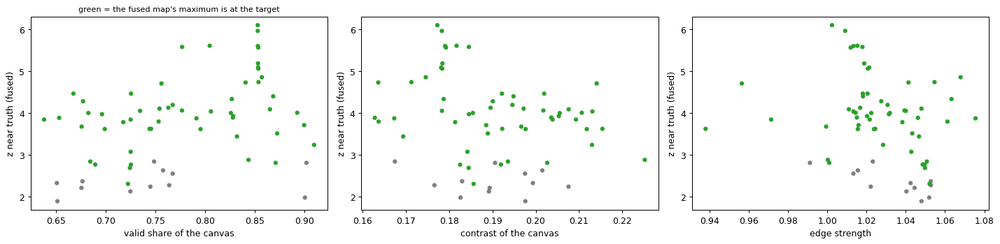

share of photos whose fused maximum is at the target, by valid share of the canvas:


,mean,count
valid_group,,
low valid share,0.773,22
middle,0.773,22
high valid share,0.909,22


In [ ]:
photo_rows = []
for record in records:
    row = dict(photo=record["index"], height=record["height"], level=record["level"], valid_frac=record["valid_frac"],
               contrast=record["contrast"], edge_strength=record["edge_strength"])
    row["near_z (%s)" % PRIMARY] = record["methods"][PRIMARY]["stats"]["near_z"]
    photo_rows.append(row)
image_table = pd.DataFrame(photo_rows)
display(image_table.drop(columns=["photo"]).describe().T[["mean", "min", "25%", "50%", "75%", "max"]].round(3))

all_map_names = list(pipeline.names)
for method_name in METHODS:
    if method_name not in all_map_names:
        all_map_names.append(method_name)
map_rows = []
for name in all_map_names:
    stats = []
    for record in records:
        if name in record["maps"]:
            stats.append(record["maps"][name])
        else:
            stats.append(record["methods"][name]["stats"])
    argmax_err = np.array([s["argmax_err"] for s in stats])
    near_z = np.array([s["near_z"] for s in stats])
    margin = np.array([s["margin"] for s in stats])
    map_rows.append({"map": name,
                     "max at target (4 sigma)": np.nanmean(argmax_err <= FOUND_SIGMA),
                     "max at target (1 sigma)": np.nanmean(argmax_err <= STRICT_SIGMA),
                     "median z near truth": np.nanmedian(near_z),
                     "z near truth > 3": np.nanmean(near_z > 3),
                     "margin > 0": np.nanmean(margin > 0)})
map_table = pd.DataFrame(map_rows)
display(map_table.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
hit = np.array([record["methods"][PRIMARY]["stats"]["argmax_err"] <= FOUND_SIGMA for record in records])
for axis, column, label in ((axes[0], "valid_frac", "valid share of the canvas"), (axes[1], "contrast", "contrast of the canvas"), (axes[2], "edge_strength", "edge strength")):
    axis.scatter(image_table[column], image_table["near_z (%s)" % PRIMARY], c=["tab:green" if h else "tab:gray" for h in hit], s=16)
    axis.set_xlabel(label)
    axis.set_ylabel("z near truth (%s)" % PRIMARY)
axes[0].set_title("green = the %s map's maximum is at the target" % PRIMARY, fontsize=9)
plt.tight_layout()
plt.show()

image_table["valid_group"] = pd.qcut(image_table["valid_frac"].rank(method="first"), 3, labels=["low valid share", "middle", "high valid share"])
image_table["map_hit"] = hit
print("share of photos whose %s maximum is at the target, by valid share of the canvas:" % PRIMARY)
display(image_table.groupby("valid_group", observed=True)["map_hit"].agg(["mean", "count"]).round(3))

## 6.2 Stage 2 · Coarse search: is the target among the chosen peaks?

**Recall at K** = the share of photos with a peak within 4 sigma (1 sigma) of the truth among the first K peaks. Recall at K = 1 is the coarse top-1. The gap between recall at 1 and recall at 50 is what a better judge of the shortlist (stage 3) could still win; the gap between recall at 50 and 100 % is lost for good at this stage.

,method,found within,recall@1,recall@3,recall@5,recall@10,recall@25,recall@50
0,edge_zncc,4 sigma,0.803,0.818,0.864,0.879,0.909,0.924
1,edge_zncc,1 sigma,0.530,0.545,0.545,0.561,0.576,0.591
2,fused,4 sigma,0.818,0.848,0.864,0.864,0.894,0.894
3,fused,1 sigma,0.545,0.576,0.576,0.576,0.576,0.576


fused: the target is in the first 100 peaks for 59 of 66 photos; rank of the first right peak: median 1, mean 1.5


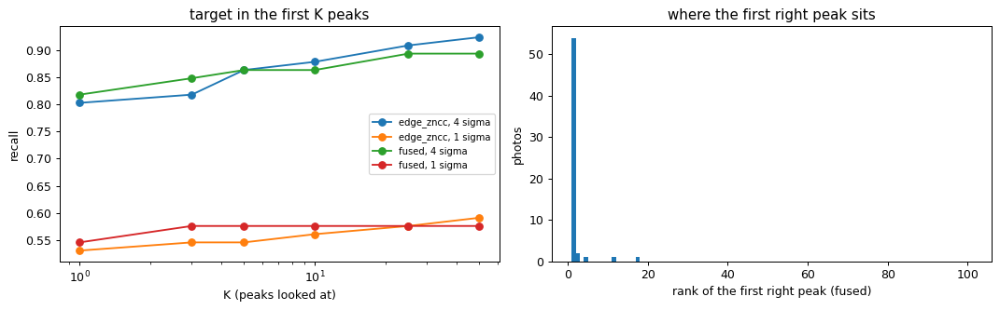

z of the best score near the truth: photos where the target is NOT in the 100 peaks: median 2.20 | photos where it is: median 3.92
(a low value means the map itself did not show the target: a stage 1 / map problem; a high value means the target was visible but another place was ranked higher)


In [ ]:
recall_ks = [k for k in (1, 3, 5, 10, 25, 50) if k <= K_MAX]
rows = []
curves = {}
for method_name in METHODS:
    for sigma_limit, label in ((FOUND_SIGMA, "%g sigma" % FOUND_SIGMA), (STRICT_SIGMA, "%g sigma" % STRICT_SIGMA)):
        row = {"method": method_name, "found within": label}
        values = []
        for k in recall_ks:
            hits = [(record["methods"][method_name]["err"][:k] <= sigma_limit).any() for record in records]
            row["recall@%d" % k] = np.mean(hits)
            values.append(np.mean(hits))
        rows.append(row)
        curves[(method_name, label)] = values
display(pd.DataFrame(rows).round(3))

first_right = []
for record in records:
    errors = record["methods"][PRIMARY]["err"]
    right = np.where(errors <= FOUND_SIGMA)[0]
    if len(right) > 0:
        first_right.append(int(right[0]) + 1)
print("%s: the target is in the first %d peaks for %d of %d photos; rank of the first right peak: median %.0f, mean %.1f" % (
    PRIMARY, K_MAX, len(first_right), len(records), np.median(first_right) if first_right else float("nan"), np.mean(first_right) if first_right else float("nan")))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for (method_name, label), values in curves.items():
    axes[0].plot(recall_ks, values, "o-", label="%s, %s" % (method_name, label))
axes[0].set_xscale("log")
axes[0].set_xlabel("K (peaks looked at)")
axes[0].set_ylabel("recall")
axes[0].set_title("target in the first K peaks")
axes[0].legend(fontsize=8)
axes[1].hist(first_right, bins=range(1, K_MAX + 2), color="tab:blue")
axes[1].set_xlabel("rank of the first right peak (%s)" % PRIMARY)
axes[1].set_ylabel("photos")
axes[1].set_title("where the first right peak sits")
plt.tight_layout()
plt.show()

misses = [record for record in records if not (record["methods"][PRIMARY]["err"][:K_MAX] <= FOUND_SIGMA).any()]
missed_photos = set(record["index"] for record in misses)
hits_list = [record for record in records if record["index"] not in missed_photos]
if len(misses) > 0 and len(hits_list) > 0:
    print("z of the best score near the truth: photos where the target is NOT in the %d peaks: median %.2f | photos where it is: median %.2f" % (
        K_MAX, np.nanmedian([record["methods"][PRIMARY]["stats"]["near_z"] for record in misses]),
        np.nanmedian([record["methods"][PRIMARY]["stats"]["near_z"] for record in hits_list])))
    print("(a low value means the map itself did not show the target: a stage 1 / map problem; a high value means the target was visible but another place was ranked higher)")

## 6.3 Stage 3 · Semantic layer (DINO)

Three questions, all on the same K (= `K_BASE`) peaks:

* **Top-1:** is the first peak right more often after DINO re-ordered the K peaks? Paired: how many photos were fixed, how many broken, and a bootstrap 95 % interval of the gain.
* **Recall at M of K:** the fine stage only gets M of the K peaks. How often is the target among them, with the coarse order and with the DINO order?
* **Separation:** within one photo's K peaks, how often does a right peak get a higher DINO score than a wrong one (0.5 = no information, 1.0 = perfect)?

In [ ]:
rng = np.random.default_rng(SEED)
rows = []
for method_name in METHODS:
    for sigma_limit, label in ((FOUND_SIGMA, "%g sigma" % FOUND_SIGMA), (STRICT_SIGMA, "%g sigma" % STRICT_SIGMA)):
        before = []
        after = []
        for record in records:
            err_plain = record["methods"][method_name]["err"][:K_BASE]
            order, err_layer = ordered_errors(record, method_name, K_BASE, 1, True, WEIGHT_BASE)
            before.append(err_plain[0] <= sigma_limit)
            after.append(err_layer[0] <= sigma_limit)
        before = np.array(before)
        after = np.array(after)
        difference = after.astype(float) - before.astype(float)
        resamples = []
        for _ in range(2000):
            pick = rng.integers(0, len(difference), len(difference))
            resamples.append(difference[pick].mean())
        low, high = np.percentile(resamples, [2.5, 97.5])
        rows.append({"coarse method": method_name, "top-1 within": label, "before": before.mean(), "after DINO": after.mean(),
                     "gain": difference.mean(), "95% low": low, "95% high": high,
                     "fixed": int((after & ~before).sum()), "broken": int((~after & before).sum())})
display(pd.DataFrame(rows).round(3))

rows = []
for method_name in METHODS:
    for m in [m for m in M_LIST if m <= K_BASE]:
        plain = []
        layered = []
        for record in records:
            err_plain = record["methods"][method_name]["err"][:m]
            order, err_layer = ordered_errors(record, method_name, K_BASE, m, True, WEIGHT_BASE)
            plain.append((err_plain <= FOUND_SIGMA).any())
            layered.append((err_layer <= FOUND_SIGMA).any())
        ceiling = np.mean([(record["methods"][method_name]["err"][:K_BASE] <= FOUND_SIGMA).any() for record in records])
        rows.append({"coarse method": method_name, "M": m, "target in first M (coarse order)": np.mean(plain),
                     "target in best M (DINO order)": np.mean(layered), "target in all K": ceiling})
display(pd.DataFrame(rows).round(3))

rank_before = []
rank_after = []
auc_values = []
for record in records:
    data = record["methods"][PRIMARY]
    err_plain = data["err"][:K_BASE]
    order, err_layer = ordered_errors(record, PRIMARY, K_BASE, K_BASE, True, WEIGHT_BASE)
    right_plain = np.where(err_plain <= FOUND_SIGMA)[0]
    right_layer = np.where(err_layer <= FOUND_SIGMA)[0]
    if len(right_plain) > 0:
        rank_before.append(right_plain[0] + 1)
        rank_after.append(right_layer[0] + 1)
    right = err_plain <= FOUND_SIGMA
    real = data["short"][:K_BASE, 1] < 1e8
    dense = data["dense"][:K_BASE]
    if right.any() and (real & ~right).any():
        good = dense[right & real][:, None]
        bad = dense[real & ~right][None, :]
        auc_values.append(((good > bad).mean() + 0.5 * (good == bad).mean()))
print("%s: rank of the first right peak among K=%d: before DINO median %.0f (mean %.1f) -> after DINO median %.0f (mean %.1f), %d photos" % (
    PRIMARY, K_BASE, np.median(rank_before), np.mean(rank_before), np.median(rank_after), np.mean(rank_after), len(rank_before)))
print("DINO separation inside the K peaks (right peak scored above a wrong one): mean %.3f over %d photos" % (np.mean(auc_values), len(auc_values)))

,coarse method,top-1 within,before,after DINO,gain,95% low,95% high,fixed,broken
0,edge_zncc,4 sigma,0.803,0.939,0.136,0.061,0.227,9,0
1,edge_zncc,1 sigma,0.530,0.591,0.061,0.015,0.121,4,0
2,fused,4 sigma,0.818,0.848,0.030,-0.045,0.106,4,2
3,fused,1 sigma,0.545,0.530,-0.015,-0.076,0.030,1,2


,coarse method,M,target in first M (coarse order),target in best M (DINO order),target in all K
0,edge_zncc,1,0.803,0.939,0.939
1,edge_zncc,3,0.818,0.939,0.939
2,edge_zncc,5,0.864,0.939,0.939
3,edge_zncc,10,0.879,0.939,0.939
4,edge_zncc,15,0.894,0.939,0.939
5,edge_zncc,25,0.909,0.939,0.939
6,edge_zncc,50,0.924,0.939,0.939
7,fused,1,0.818,0.848,0.894
8,fused,3,0.848,0.879,0.894
9,fused,5,0.864,0.879,0.894


fused: rank of the first right peak among K=100: before DINO median 1 (mean 1.5) -> after DINO median 1 (mean 1.2), 59 photos
DINO separation inside the K peaks (right peak scored above a wrong one): mean 0.998 over 59 photos


## 6.4 Stage 4 · Fine matching: if the target is among the M, does the matcher find it?

For the photos where a right candidate is among the M that go to the fine stage:

* **right has most inliers:** the best right candidate has more inliers than the best wrong one (the matcher separates them).
* **right has 0 inliers:** the matcher found nothing at the target (matcher failure, or the shift was rejected).
* **separation:** within a photo, how often a right candidate has more inliers than a wrong one (0.5 = no information).
* **median inliers right / wrong:** the typical best count of right and wrong candidates. The distance between them shows where the answer bar can sit.
* **error after the shift:** how close the corrected position of the chosen right candidate gets (the precision of the matcher).

,matcher,photos with the target in M,right has most inliers,right has 0 inliers,separation (right > wrong),"median best inliers, right","median best inliers, wrong",median error after shift (sigma),answered within 1 sigma,seconds per photo (K_MAX candidates)
0,loftr_minima,59,0.949,0.051,0.975,23.0,0.0,0.609,0.939,7.412


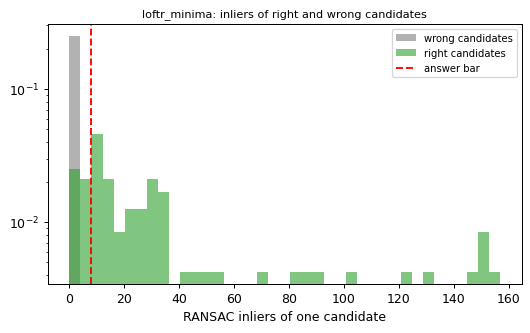

In [ ]:
rows = []
for name in MATCHERS:
    wins = []
    zero = []
    auc_list = []
    inliers_right = []
    inliers_wrong = []
    for record in records:
        order, errors = ordered_errors(record, PRIMARY, BASE["K"], BASE["M"], BASE["layer"], BASE["weight"])
        inliers = fine[name][record["index"]]["inliers"][order]
        right = errors <= FOUND_SIGMA
        if not right.any():
            continue
        best_right = inliers[right].max()
        inliers_right.append(best_right)
        zero.append(best_right == 0)
        if (~right).any():
            best_wrong = inliers[~right].max()
            inliers_wrong.append(best_wrong)
            wins.append(best_right > best_wrong)
            good = inliers[right][:, None]
            bad = inliers[~right][None, :]
            auc_list.append(((good > bad).mean() + 0.5 * (good == bad).mean()))
    table = base[name]
    chosen_ok = table[table["chosen_right"] & table["answered"]]
    rows.append({"matcher": name, "photos with the target in M": len(inliers_right),
                 "right has most inliers": np.mean(wins), "right has 0 inliers": np.mean(zero),
                 "separation (right > wrong)": np.mean(auc_list),
                 "median best inliers, right": np.median(inliers_right), "median best inliers, wrong": np.median(inliers_wrong),
                 "median error after shift (sigma)": chosen_ok["err_sigma"].median() if len(chosen_ok) > 0 else np.nan,
                 "answered within 1 sigma": (chosen_ok["err_sigma"] <= STRICT_SIGMA).mean() if len(chosen_ok) > 0 else np.nan,
                 "seconds per photo (K_MAX candidates)": fine_seconds[name] / len(records)})
display(pd.DataFrame(rows).round(3))

fig, axes = plt.subplots(1, len(MATCHERS), figsize=(6 * len(MATCHERS), 3.8), squeeze=False)
for position, name in enumerate(MATCHERS):
    right_values = []
    wrong_values = []
    for record in records:
        order, errors = ordered_errors(record, PRIMARY, BASE["K"], BASE["M"], BASE["layer"], BASE["weight"])
        inliers = fine[name][record["index"]]["inliers"][order]
        right_values.extend(list(inliers[errors <= FOUND_SIGMA]))
        wrong_values.extend(list(inliers[errors > FOUND_SIGMA]))
    top = max(max(right_values + [1]), max(wrong_values + [1]))
    bins = np.linspace(0, top, 40)
    axes[0, position].hist(wrong_values, bins=bins, alpha=0.6, color="tab:gray", label="wrong candidates", density=True)
    axes[0, position].hist(right_values, bins=bins, alpha=0.6, color="tab:green", label="right candidates", density=True)
    axes[0, position].axvline(BASE["bar"], color="red", ls="--", label="answer bar")
    axes[0, position].set_yscale("log")
    axes[0, position].set_xlabel("RANSAC inliers of one candidate")
    axes[0, position].set_title("%s: inliers of right and wrong candidates" % name, fontsize=9)
    axes[0, position].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6.5 Stage 5 · Decision: does it answer the right photos?

* **precision:** among the answered photos, the share within 4 sigma (and within 1 sigma).
* **answerable and answered:** among photos whose chosen position is within 4 sigma, the share that was answered.
* **points lost by skipping:** the points the skipped right answers would have earned.
* **points lost to wrong answers:** the points taken away by answers beyond 8 sigma (each −20).
* The sweep over the answer bar (and gamma and the rescue rule) is in Part 8; this part reports the baseline.

In [ ]:
rows = []
for name in MATCHERS:
    table = base[name]
    answered = table[table["answered"]]
    answerable = table[table["err_sigma"] <= FOUND_SIGMA]
    skipped_right = table[(~table["answered"]) & (table["err_sigma"] <= FOUND_SIGMA)]
    wrong = table[table["points"] < 0]
    rows.append({"matcher": name, "answered": table["answered"].mean(),
                 "precision (4 sigma)": (answered["err_sigma"] <= FOUND_SIGMA).mean() if len(answered) > 0 else np.nan,
                 "precision (1 sigma)": (answered["err_sigma"] <= STRICT_SIGMA).mean() if len(answered) > 0 else np.nan,
                 "answerable photos": len(answerable), "answerable and answered": answerable["answered"].mean() if len(answerable) > 0 else np.nan,
                 "points lost by skipping (/photos)": float(skipped_right["would_earn"].sum()) / len(table),
                 "wrong answers": len(wrong), "points lost to wrong answers (/photos)": 20.0 * len(wrong) / len(table)})
display(pd.DataFrame(rows).round(3))
print("points lost are shown as points per photo: multiply by 6 for the effect on the score out of 60")

,matcher,answered,precision (4 sigma),precision (1 sigma),answerable photos,answerable and answered,points lost by skipping (/photos),wrong answers,points lost to wrong answers (/photos)
0,loftr_minima,0.742,1.0,0.939,58,0.845,1.242,0,0.0


points lost are shown as points per photo: multiply by 6 for the effect on the score out of 60


## 6.6 Stage 6 · End to end: where do the points go?

The funnel follows each photo until the first stage that loses it. The **ceiling** next to each step is the score out of 60 if every photo that is still alive at that step were answered perfectly (+10) and the rest got 0: it shows how much each stage takes away.

matcher: loftr_minima | actual score 43.45 /60


,step,photos,share,lost here,ceiling score (/60)
0,all photos,66,1.000,0,60.000
1,target in the K peaks (coarse),59,0.894,7,53.636
2,target in the M sent to fine (DINO / M),59,0.894,0,53.636
3,right candidate chosen (fine),58,0.879,1,52.727
4,answered (decision),49,0.742,9,44.545
5,... and within 4 sigma,49,0.742,0,44.545
6,... and within 1 sigma,46,0.697,3,41.818


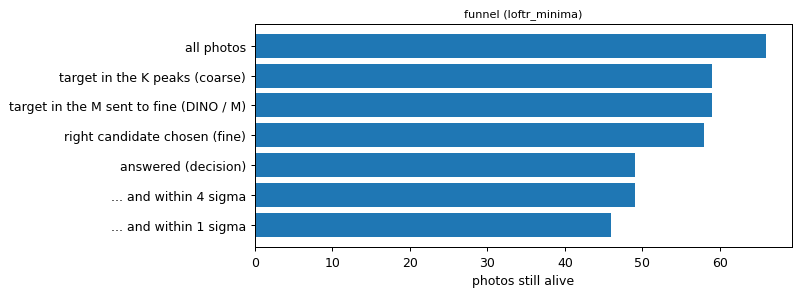

by flight height (loftr_minima):


,photos,score (/60),answered,target in K,target in M,right chosen | in M
height group,,,,,,
low,22.0,35.455,0.591,0.818,0.818,0.944
middle,22.0,56.182,0.955,1.000,1.000,1.000
high,22.0,38.727,0.682,0.864,0.864,1.000


In [ ]:
for name in MATCHERS:
    table = base[name]
    total = len(table)
    answered_ok4 = table["answered"] & (table["err_sigma"] <= FOUND_SIGMA)
    answered_ok1 = table["answered"] & (table["err_sigma"] <= STRICT_SIGMA)
    steps = [("all photos", np.ones(total, dtype=bool)),
             ("target in the K peaks (coarse)", table["in_K"].to_numpy()),
             ("target in the M sent to fine (DINO / M)", (table["in_K"] & table["in_M"]).to_numpy()),
             ("right candidate chosen (fine)", (table["in_K"] & table["in_M"] & table["chosen_right"]).to_numpy()),
             ("answered (decision)", (table["in_K"] & table["in_M"] & table["chosen_right"] & table["answered"]).to_numpy()),
             ("... and within 4 sigma", answered_ok4.to_numpy()),
             ("... and within 1 sigma", answered_ok1.to_numpy())]
    rows = []
    previous = total
    for label, alive in steps:
        rows.append({"step": label, "photos": int(alive.sum()), "share": alive.mean(), "lost here": previous - int(alive.sum()),
                     "ceiling score (/60)": 60 * alive.mean()})
        previous = int(alive.sum())
    print("matcher:", name, "| actual score %.2f /60" % final_score(list(table["points"])))
    display(pd.DataFrame(rows).round(3))

    fig, axis = plt.subplots(figsize=(9, 3.4))
    axis.barh([row["step"] for row in rows][::-1], [row["photos"] for row in rows][::-1], color="tab:blue")
    axis.set_xlabel("photos still alive")
    axis.set_title("funnel (%s)" % name, fontsize=9)
    plt.tight_layout()
    plt.show()

main = base[MATCHERS[0]].copy()
main["height"] = [record_by_index[p]["height"] for p in main["photo"]]
main["height group"] = pd.qcut(main["height"].rank(method="first"), 3, labels=["low", "middle", "high"])
print("by flight height (%s):" % MATCHERS[0])
display(main.groupby("height group", observed=True).apply(lambda g: pd.Series({
    "photos": len(g), "score (/60)": final_score(list(g["points"])), "answered": g["answered"].mean(),
    "target in K": g["in_K"].mean(), "target in M": g["in_M"].mean(), "right chosen | in M": g["chosen_right"][g["in_M"]].mean() if g["in_M"].any() else np.nan})).round(3))

# Part 7 · Image processing sample: render and map agreement

The photos where the score maps see the target least clearly (lowest z near the truth, from 6.1) and the photos where they see it best. For each: the north-up canvas, the true map tile and the canvas laid over it. This is the quickest check of the geometry and the cleaned thermal photo.

lowest z near the truth (the target is hardest to see in the map)


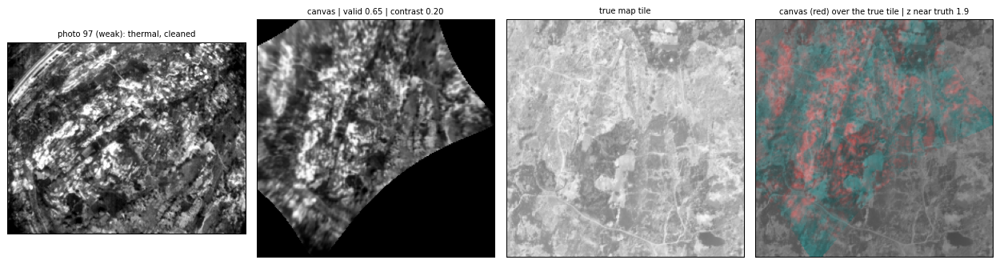

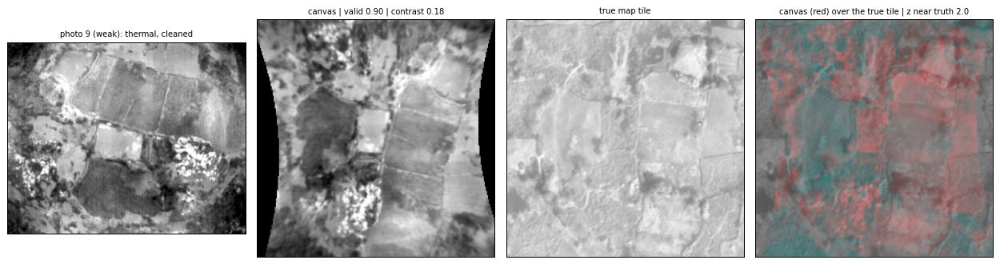

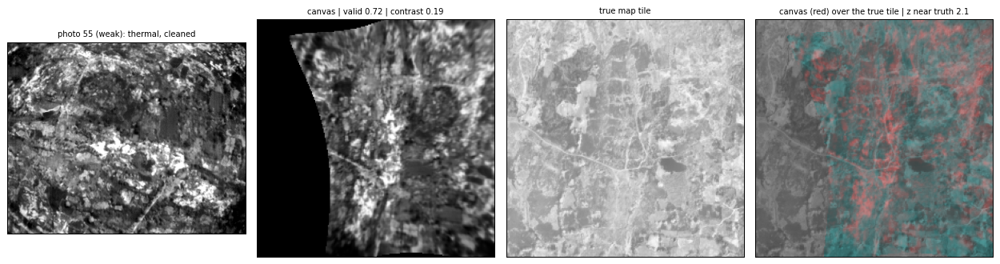

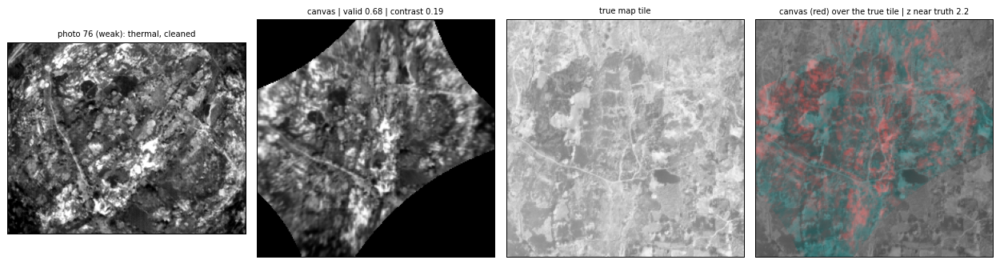

highest z near the truth


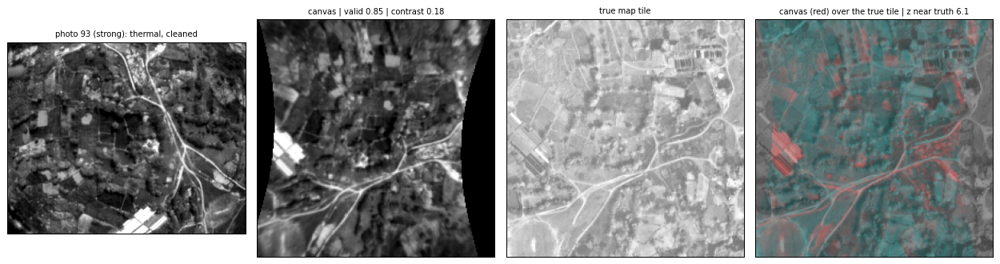

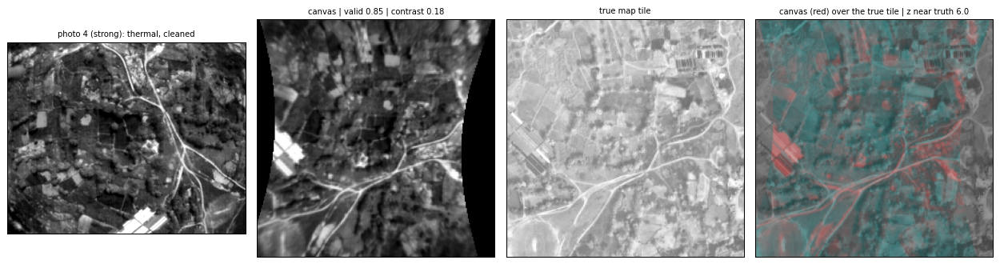

In [ ]:
def show(axis, picture, title="", cmap="gray", vmin=0, vmax=1):
    axis.imshow(picture, cmap=cmap, vmin=vmin, vmax=vmax)
    axis.set_title(title, fontsize=8)
    axis.set_xticks([])
    axis.set_yticks([])


def show_render(index, label):
    record = record_by_index[index]
    item = test_set.items[index]
    truth = record["truth"]
    true_tile = map_piece(level_images, record["level"], truth[0], truth[1])
    frame = normalise_frame(load_thermal_frame(item))
    blend = np.stack([true_tile, true_tile, true_tile], axis=-1) * 0.6
    blend[..., 0] = np.where(record["valid"], 0.5 * blend[..., 0] + 0.5 * record["canvas"], blend[..., 0])
    fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
    show(axes[0], frame, "photo %d (%s): thermal, cleaned" % (index, label))
    show(axes[1], record["canvas"] * record["valid"], "canvas | valid %.2f | contrast %.2f" % (record["valid_frac"], record["contrast"]))
    show(axes[2], true_tile, "true map tile")
    show(axes[3], np.clip(blend, 0, 1), "canvas (red) over the true tile | z near truth %.1f" % record["methods"][PRIMARY]["stats"]["near_z"])
    plt.tight_layout()
    plt.show()


ranked = sorted(records, key=lambda r: (np.nan_to_num(r["methods"][PRIMARY]["stats"]["near_z"], nan=-99.0)))
print("lowest z near the truth (the target is hardest to see in the map)")
for record in ranked[:N_SAMPLES]:
    show_render(record["index"], "weak")
print("highest z near the truth")
for record in ranked[::-1][:min(2, N_SAMPLES)]:
    show_render(record["index"], "strong")

# Part 8 · Hyperparameter sweeps (from the stored numbers, no new matching)

Every row re-scores the same 100 photos with a different setting. Reading guide: look at **target in K / target in M** to see what a stage allows at most, at **right chosen | target in M** to see what the fine stage and decision do with it, and at the two halves. A setting that is best in one half and not in the other is noise.

## 8.1 K, M and DINO weight

`weight = 0` is the coarse order. `layer off` takes the first M of the coarse order (no DINO).

In [ ]:
rows = []
for K in K_LIST:
    for M in M_LIST:
        if M > K:
            continue
        for weight in WEIGHT_LIST:
            cfg = dict(BASE, K=K, M=M, weight=weight, layer=True)
            row = {"K": K, "M": M, "weight": weight}
            row.update(summarise(evaluate(cfg, MATCHERS[0])))
            rows.append(row)
for M in M_LIST:
    cfg = dict(BASE, K=K_BASE, M=M, layer=False)
    row = {"K": K_BASE, "M": M, "weight": -1}
    row.update(summarise(evaluate(cfg, MATCHERS[0])))
    rows.append(row)
sweep_kmw = pd.DataFrame(rows)
sweep_kmw["weight"] = sweep_kmw["weight"].replace(-1, np.nan)
print("matcher:", MATCHERS[0], "| bar", BASE["bar"], "| gamma", BASE["gamma"], "| rows with weight NaN = layer off")
display(sweep_kmw.sort_values("score (/60)", ascending=False).head(15).round(3).reset_index(drop=True))
print("score by M (rows) and DINO weight (columns), K =", K_BASE)
display(sweep_kmw[(sweep_kmw["K"] == K_BASE) & sweep_kmw["weight"].notna()].pivot_table(index="M", columns="weight", values="score (/60)").round(2))
print("target in M by M (rows) and DINO weight (columns), K =", K_BASE)
display(sweep_kmw[(sweep_kmw["K"] == K_BASE) & sweep_kmw["weight"].notna()].pivot_table(index="M", columns="weight", values="target in M").round(3))
print("layer off (first M of the coarse order):")
display(sweep_kmw[sweep_kmw["weight"].isna()].drop(columns=["weight"]).round(3).reset_index(drop=True))

matcher: loftr_minima | bar 8 | gamma 1.0 | rows with weight NaN = layer off


,K,M,weight,score (/60),first half,second half,answered,target in K,target in M,top-1 ok,right chosen | target in M,answered and ok,wrong answers,right but skipped
0,100,50,NaN,43.455,37.455,49.455,0.742,0.894,0.894,0.818,0.983,0.742,0,9
1,50,10,100.0,43.455,37.455,49.455,0.742,0.894,0.894,0.879,1.000,0.742,0,10
2,50,5,3.0,43.455,37.455,49.455,0.742,0.894,0.894,0.894,1.000,0.742,0,10
3,50,5,10.0,43.455,37.455,49.455,0.742,0.894,0.894,0.879,1.000,0.742,0,10
4,50,10,0.3,43.455,37.455,49.455,0.742,0.894,0.894,0.848,0.983,0.742,0,9
5,50,10,1.0,43.455,37.455,49.455,0.742,0.894,0.894,0.894,1.000,0.742,0,10
6,50,10,3.0,43.455,37.455,49.455,0.742,0.894,0.894,0.894,1.000,0.742,0,10
7,50,10,10.0,43.455,37.455,49.455,0.742,0.894,0.894,0.879,1.000,0.742,0,10
8,50,15,0.0,43.455,37.455,49.455,0.742,0.894,0.879,0.818,0.983,0.742,0,8
9,50,25,1.0,43.455,37.455,49.455,0.742,0.894,0.894,0.894,1.000,0.742,0,10


score by M (rows) and DINO weight (columns), K = 100


weight,0.0,0.3,1.0,3.0,10.0,100.0
M,,,,,,
1,41.64,43.45,43.45,43.45,42.55,42.55
3,41.64,43.45,43.45,43.45,42.55,42.55
5,42.55,43.45,43.45,43.45,43.45,42.55
10,42.55,43.45,43.45,43.45,43.45,43.45
15,43.45,43.45,43.45,43.45,43.45,43.45
25,43.45,43.45,43.45,43.45,43.45,43.45
50,43.45,43.45,43.45,43.45,43.45,43.45


target in M by M (rows) and DINO weight (columns), K = 100


weight,0.0,0.3,1.0,3.0,10.0,100.0
M,,,,,,
1,0.818,0.879,0.894,0.894,0.864,0.848
3,0.848,0.894,0.894,0.894,0.879,0.879
5,0.864,0.894,0.894,0.894,0.894,0.879
10,0.864,0.894,0.894,0.894,0.894,0.894
15,0.879,0.894,0.894,0.894,0.894,0.894
25,0.894,0.894,0.894,0.894,0.894,0.894
50,0.894,0.894,0.894,0.894,0.894,0.894


layer off (first M of the coarse order):


,K,M,score (/60),first half,second half,answered,target in K,target in M,top-1 ok,right chosen | target in M,answered and ok,wrong answers,right but skipped
0,100,1,41.636,35.636,47.636,0.712,0.894,0.818,0.818,1.000,0.712,0,7
1,100,3,41.636,35.636,47.636,0.712,0.894,0.848,0.818,0.982,0.712,0,8
2,100,5,42.545,35.636,49.455,0.727,0.894,0.864,0.818,0.982,0.727,0,8
3,100,10,42.545,35.636,49.455,0.727,0.894,0.864,0.818,0.982,0.727,0,8
4,100,15,43.455,37.455,49.455,0.742,0.894,0.879,0.818,0.983,0.742,0,8
5,100,25,43.455,37.455,49.455,0.742,0.894,0.894,0.818,0.983,0.742,0,9
6,100,50,43.455,37.455,49.455,0.742,0.894,0.894,0.818,0.983,0.742,0,9


## 8.2 Answer bar, gamma and rescue rule, per matcher

The bar is the number of inliers the chosen place needs. `gamma` adds the DINO z-score to the inlier count when the candidate is chosen. The rescue rule also answers with fewer inliers when DINO is confident. Everything is evaluated for each matcher in `MATCHERS`, because the inlier scales differ.

,matcher,bar,gamma,rescue,score (/60),first half,second half,answered,target in K,target in M,top-1 ok,right chosen | target in M,answered and ok,wrong answers,right but skipped
0,loftr_minima,1,0.00,None,49.091,46.909,51.273,0.848,0.894,0.894,0.848,0.983,0.848,0,2
1,loftr_minima,3,0.50,"(0, 3.0)",49.091,46.909,51.273,0.848,0.894,0.894,0.848,0.983,0.848,0,2
2,loftr_minima,3,0.50,"(6, 2.0)",49.091,46.909,51.273,0.848,0.894,0.894,0.848,0.983,0.848,0,2
3,loftr_minima,3,0.50,"(4, 2.0)",49.091,46.909,51.273,0.848,0.894,0.894,0.848,0.983,0.848,0,2
4,loftr_minima,3,0.50,None,49.091,46.909,51.273,0.848,0.894,0.894,0.848,0.983,0.848,0,2
5,loftr_minima,3,0.25,"(0, 3.5)",49.091,46.909,51.273,0.848,0.894,0.894,0.848,0.983,0.848,0,2
6,loftr_minima,3,0.25,"(0, 3.0)",49.091,46.909,51.273,0.848,0.894,0.894,0.848,0.983,0.848,0,2
7,loftr_minima,3,0.25,"(8, 2.5)",49.091,46.909,51.273,0.848,0.894,0.894,0.848,0.983,0.848,0,2
8,loftr_minima,3,0.25,"(6, 2.0)",49.091,46.909,51.273,0.848,0.894,0.894,0.848,0.983,0.848,0,2
9,loftr_minima,3,0.25,"(4, 2.0)",49.091,46.909,51.273,0.848,0.894,0.894,0.848,0.983,0.848,0,2


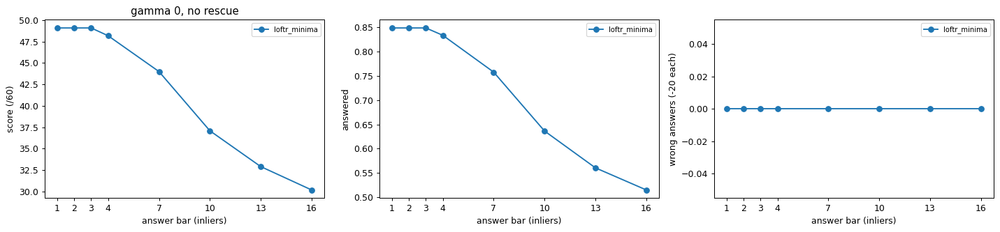

score by gamma (rows) and rescue rule (columns), matcher loftr_minima, bar 8


rescue
gamma


In [ ]:
rows = []
for name in MATCHERS:
    for bar in BAR_LIST:
        for gamma in GAMMA_LIST:
            for rescue in RESCUE_LIST:
                cfg = dict(BASE, bar=bar, gamma=gamma, rescue=rescue)
                row = {"matcher": name, "bar": bar, "gamma": gamma, "rescue": str(rescue)}
                row.update(summarise(evaluate(cfg, name)))
                rows.append(row)
sweep_bar = pd.DataFrame(rows)
display(sweep_bar.sort_values("score (/60)", ascending=False).head(15).round(3).reset_index(drop=True))

plain = sweep_bar[(sweep_bar["gamma"] == 0.0) & (sweep_bar["rescue"] == "None")]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for name in MATCHERS:
    part = plain[plain["matcher"] == name]
    axes[0].plot(part["bar"], part["score (/60)"], "o-", label=name)
    axes[1].plot(part["bar"], part["answered"], "o-", label=name)
    axes[2].plot(part["bar"], part["wrong answers"], "o-", label=name)
axes[0].set_ylabel("score (/60)")
axes[1].set_ylabel("answered")
axes[2].set_ylabel("wrong answers (-20 each)")
for axis in axes:
    axis.set_xlabel("answer bar (inliers)")
    axis.set_xticks(BAR_LIST)
    axis.legend(fontsize=8)
axes[0].set_title("gamma 0, no rescue")
plt.tight_layout()
plt.show()

print("score by gamma (rows) and rescue rule (columns), matcher %s, bar %d" % (MATCHERS[0], BASE["bar"]))
part = sweep_bar[(sweep_bar["matcher"] == MATCHERS[0]) & (sweep_bar["bar"] == BASE["bar"])]
display(part.pivot_table(index="gamma", columns="rescue", values="score (/60)").round(2))

## 8.3 Best setting per matcher, with both halves

The best row of the answer sweep for each matcher next to the baseline. If the best row's gain is not there in both halves, do not use it.

In [ ]:
rows = []
for name in MATCHERS:
    part = sweep_bar[sweep_bar["matcher"] == name].sort_values("score (/60)", ascending=False)
    best = part.iloc[0]
    reference = summarise(base[name])
    rows.append({"matcher": name, "which": "baseline", "bar": BASE["bar"], "gamma": BASE["gamma"], "rescue": str(BASE["rescue"]),
                 "score (/60)": reference["score (/60)"], "first half": reference["first half"], "second half": reference["second half"],
                 "answered": reference["answered"], "wrong answers": reference["wrong answers"]})
    rows.append({"matcher": name, "which": "best of the sweep", "bar": best["bar"], "gamma": best["gamma"], "rescue": best["rescue"],
                 "score (/60)": best["score (/60)"], "first half": best["first half"], "second half": best["second half"],
                 "answered": best["answered"], "wrong answers": best["wrong answers"]})
display(pd.DataFrame(rows).round(3))

,matcher,which,bar,gamma,rescue,score (/60),first half,second half,answered,wrong answers
0,loftr_minima,baseline,8,1.0,None,43.455,37.455,49.455,0.742,0
1,loftr_minima,best of the sweep,1,0.0,None,49.091,46.909,51.273,0.848,0


## 8.4 Score against every hyperparameter

Each panel moves **one** hyperparameter over its logical range (the lists in the settings cell) and keeps all the others at the baseline. Blue is the score of all photos, the dashed lines are the two halves (if they disagree, the difference is noise), the grey line is the share answered, and red marks the baseline value. The table below the figure ranks the hyperparameters by how far the score moves over their range: that is the order in which they are worth tuning.

`LoFTR confidence` and `RANSAC distance` are re-fitted from the matches stored in pass B (the network does not run again). They are only available when the first matcher is `loftr_minima`.

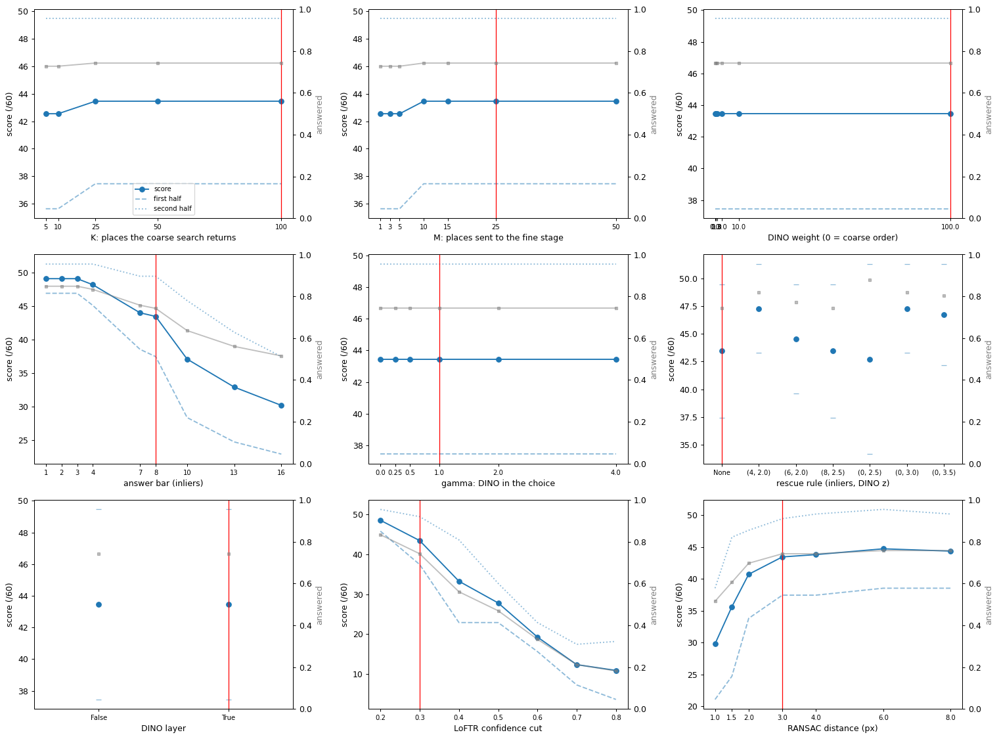

one hyperparameter moved at a time, the others at the baseline (matcher loftr_minima); the largest range is the one that matters most:


,hyperparameter,baseline,best value,score at best,score at baseline,score range over the sweep
0,LoFTR confidence cut,0.3,0.2,48.55,43.45,37.64
1,answer bar (inliers),8,1.0,49.09,43.45,18.91
2,RANSAC distance (px),3.0,6.0,44.73,43.45,14.91
3,"rescue rule (inliers, DINO z)",None,"(4, 2.0)",47.27,43.45,4.55
4,K: places the coarse search returns,100,25.0,43.45,43.45,0.91
5,M: places sent to the fine stage,25,10.0,43.45,43.45,0.91
6,DINO weight (0 = coarse order),100.0,0.0,43.45,43.45,0.00
7,gamma: DINO in the choice,1.0,0.0,43.45,43.45,0.00
8,DINO layer,True,False,43.45,43.45,0.00


In [ ]:
def sweep_one(values, make_row):
    rows = []
    for value in values:
        row = dict(make_row(value))
        row["value"] = value
        rows.append(row)
    return pd.DataFrame(rows)


LOFTR_SWEEP = MATCHERS[0] in raw_matches
BASE_CONF = MATCHER_CONFIDENCE
BASE_PX = pipeline.ransac_pixels


def fine_variant(conf, px):
    """The fine-stage numbers of the first matcher re-fitted from its stored LoFTR matches with another confidence cut and RANSAC distance.
    Returns the key under which they are stored in `fine`, so that evaluate(cfg, key) scores them."""
    assert LOFTR_SWEEP, "stored matches exist only for loftr_minima as the first matcher"
    key = "%s|conf%.2f|px%.2f" % (MATCHERS[0], conf, px)
    if key not in fine:
        stored = {}
        for record in records:
            cv2.setRNGSeed(settings.SEED)
            stage2 = stage2_from_matches(raw_matches[MATCHERS[0]][record["index"]], record["level"], conf, px)
            stored[record["index"]] = dict(inliers=np.asarray(stage2["inliers"], dtype=float), shifts=np.asarray(stage2["shifts"], dtype=float))
        fine[key] = stored
    return key


def score_row(cfg, key=None):
    return summarise(evaluate(cfg, key or MATCHERS[0]))


def with_baseline(values, baseline):
    """The sweep values with the baseline value in them (so that the table can say what the baseline scores)."""
    return sorted(set(values) | {baseline})


# (title, values, row for one value, baseline value, numeric?)
PANELS = [
    ("K: places the coarse search returns", with_baseline([k for k in K_LIST if k <= K_MAX], BASE["K"]), lambda v: score_row(dict(BASE, K=v, M=min(BASE["M"], v))), BASE["K"], True),
    ("M: places sent to the fine stage", with_baseline([m for m in M_LIST if m <= BASE["K"]], BASE["M"]), lambda v: score_row(dict(BASE, M=v)), BASE["M"], True),
    ("DINO weight (0 = coarse order)", with_baseline(WEIGHT_LIST, BASE["weight"]), lambda v: score_row(dict(BASE, weight=v, layer=True)), BASE["weight"], True),
    ("answer bar (inliers)", with_baseline(BAR_LIST, BASE["bar"]), lambda v: score_row(dict(BASE, bar=v)), BASE["bar"], True),
    ("gamma: DINO in the choice", with_baseline(GAMMA_LIST, BASE["gamma"]), lambda v: score_row(dict(BASE, gamma=v, layer=True)), BASE["gamma"], True),
    ("rescue rule (inliers, DINO z)", RESCUE_LIST, lambda v: score_row(dict(BASE, rescue=v, layer=True)), BASE["rescue"], False),
    ("DINO layer", [False, True], lambda v: score_row(dict(BASE, layer=v)), BASE["layer"], False),
]
if LOFTR_SWEEP:
    PANELS.append(("LoFTR confidence cut", with_baseline(CONF_LIST, BASE_CONF), lambda v: score_row(BASE, fine_variant(v, BASE_PX)), BASE_CONF, True))
    PANELS.append(("RANSAC distance (px)", with_baseline(RANSAC_LIST, BASE_PX), lambda v: score_row(BASE, fine_variant(BASE_CONF, v)), BASE_PX, True))

columns = 3
rows_needed = (len(PANELS) + columns - 1) // columns
fig, axes = plt.subplots(rows_needed, columns, figsize=(17, 4.2 * rows_needed), squeeze=False)
summary_rows = []
for axis, (title, values, make_row, baseline, numeric) in zip(axes.ravel(), PANELS):
    table = sweep_one(values, make_row)
    position = np.array(table["value"], dtype=float) if numeric else np.arange(len(table))
    axis.plot(position, table["score (/60)"], "o-" if numeric else "o", color="tab:blue", label="score")
    axis.plot(position, table["first half"], "--" if numeric else "_", color="tab:blue", alpha=0.5, label="first half")
    axis.plot(position, table["second half"], ":" if numeric else "_", color="tab:blue", alpha=0.5, label="second half")
    side = axis.twinx()
    side.plot(position, table["answered"], "s-" if numeric else "s", color="gray", alpha=0.5, ms=3)
    side.set_ylabel("answered", color="gray")
    side.set_ylim(0, 1)
    axis.set_xlabel(title)
    axis.set_ylabel("score (/60)")
    labels = [str(v) for v in table["value"]]
    if numeric:
        axis.set_xticks(position)
        axis.set_xticklabels(labels, fontsize=8)
        axis.axvline(float(baseline), color="red", lw=1)
    else:
        axis.set_xticks(position)
        axis.set_xticklabels(labels, fontsize=8)
        mark = [i for i, v in enumerate(table["value"]) if str(v) == str(baseline)]
        if mark:
            axis.axvline(mark[0], color="red", lw=1)
        axis.set_xlim(-0.5, len(table) - 0.5)
    best = table.sort_values("score (/60)", ascending=False).iloc[0]
    at_base = table[[str(v) == str(baseline) for v in table["value"]]]
    summary_rows.append({"hyperparameter": title, "baseline": baseline, "best value": best["value"], "score at best": best["score (/60)"],
                         "score at baseline": float(at_base["score (/60)"].iloc[0]) if len(at_base) > 0 else np.nan,
                         "score range over the sweep": float(table["score (/60)"].max() - table["score (/60)"].min())})
for axis in axes.ravel()[len(PANELS):]:
    axis.axis("off")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("one hyperparameter moved at a time, the others at the baseline (matcher %s); the largest range is the one that matters most:" % MATCHERS[0])
sensitivity = pd.DataFrame(summary_rows).sort_values("score range over the sweep", ascending=False).reset_index(drop=True)
display(sensitivity.round(2))
if not LOFTR_SWEEP:
    print("LoFTR confidence and RANSAC distance are not shown: they need loftr_minima as the first matcher.")


## 8.5 Two hyperparameters together

The one-at-a-time panels miss interactions. Each heat map moves two hyperparameters over their ranges (the others at the baseline); the number in a cell is the score out of 60. The answer bar and the matching settings interact most: a stricter RANSAC distance gives fewer inliers, so the right bar moves with it.

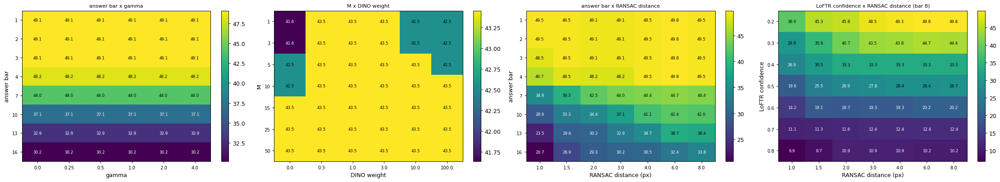

In [ ]:
def heat_map(axis, row_values, column_values, make_score, row_name, column_name, title):
    grid = np.zeros((len(row_values), len(column_values)))
    for i, row_value in enumerate(row_values):
        for j, column_value in enumerate(column_values):
            grid[i, j] = make_score(row_value, column_value)
    image = axis.imshow(grid, cmap="viridis", aspect="auto")
    axis.set_xticks(range(len(column_values)))
    axis.set_xticklabels([str(v) for v in column_values], fontsize=8)
    axis.set_yticks(range(len(row_values)))
    axis.set_yticklabels([str(v) for v in row_values], fontsize=8)
    axis.set_xlabel(column_name)
    axis.set_ylabel(row_name)
    axis.set_title(title, fontsize=9)
    middle = (grid.max() + grid.min()) / 2
    for i in range(len(row_values)):
        for j in range(len(column_values)):
            axis.text(j, i, "%.1f" % grid[i, j], ha="center", va="center", fontsize=7, color="white" if grid[i, j] < middle else "black")
    plt.colorbar(image, ax=axis, fraction=0.046)
    return grid


pairs = [
    ("answer bar", BAR_LIST, "gamma", GAMMA_LIST, lambda r, c: summarise(evaluate(dict(BASE, bar=r, gamma=c, layer=True), MATCHERS[0]))["score (/60)"], "answer bar x gamma"),
    ("M", [m for m in M_LIST if m <= BASE["K"]], "DINO weight", WEIGHT_LIST, lambda r, c: summarise(evaluate(dict(BASE, M=r, weight=c, layer=True), MATCHERS[0]))["score (/60)"], "M x DINO weight"),
]
if LOFTR_SWEEP:
    pairs.append(("answer bar", BAR_LIST, "RANSAC distance (px)", RANSAC_LIST,
                  lambda r, c: summarise(evaluate(dict(BASE, bar=r), fine_variant(BASE_CONF, c)))["score (/60)"], "answer bar x RANSAC distance"))
    pairs.append(("LoFTR confidence", CONF_LIST, "RANSAC distance (px)", RANSAC_LIST,
                  lambda r, c: summarise(evaluate(BASE, fine_variant(r, c)))["score (/60)"], "LoFTR confidence x RANSAC distance (bar %d)" % BASE["bar"]))
fig, axes = plt.subplots(1, len(pairs), figsize=(6.2 * len(pairs), 4.6), squeeze=False)
for axis, (row_name, row_values, column_name, column_values, make_score, title) in zip(axes[0], pairs):
    heat_map(axis, row_values, column_values, make_score, row_name, column_name, title)
plt.tight_layout()
plt.show()


# Part 9 · Sample figures: what the failures look like

For each kind of failure (the first stage that lost the photo, from the baseline setting), the worst `N_SAMPLES` photos, plus a few good ones. Each figure shows, left to right and top to bottom: the north-up canvas, the true map tile, the canvas over the true tile, the coarse score map (green star = truth, squares = best peaks); then the error of the first K peaks by coarse rank (green = right), the error of the M peaks after the DINO order, the inliers of those M candidates (green = right place, red line = answer bar), and the map tile of the candidate the pipeline chose.

target not in the K coarse peaks: 7 photos


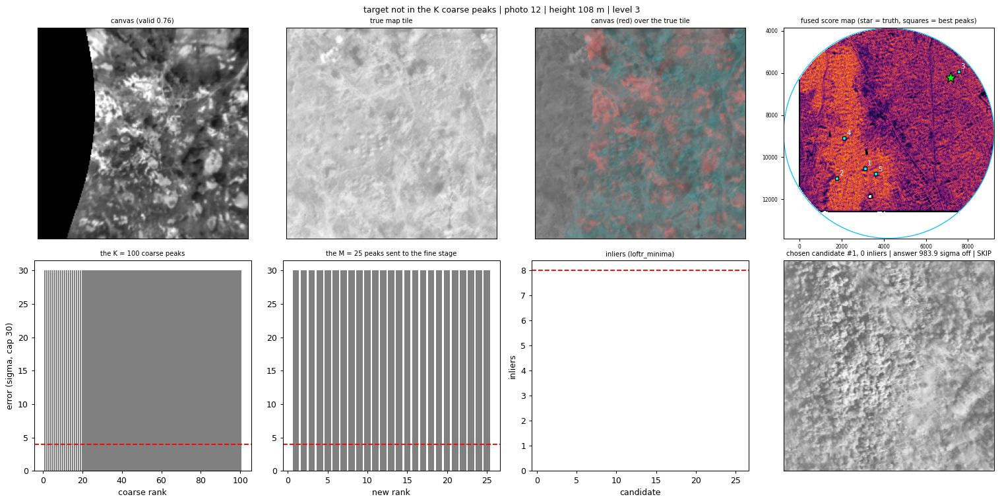

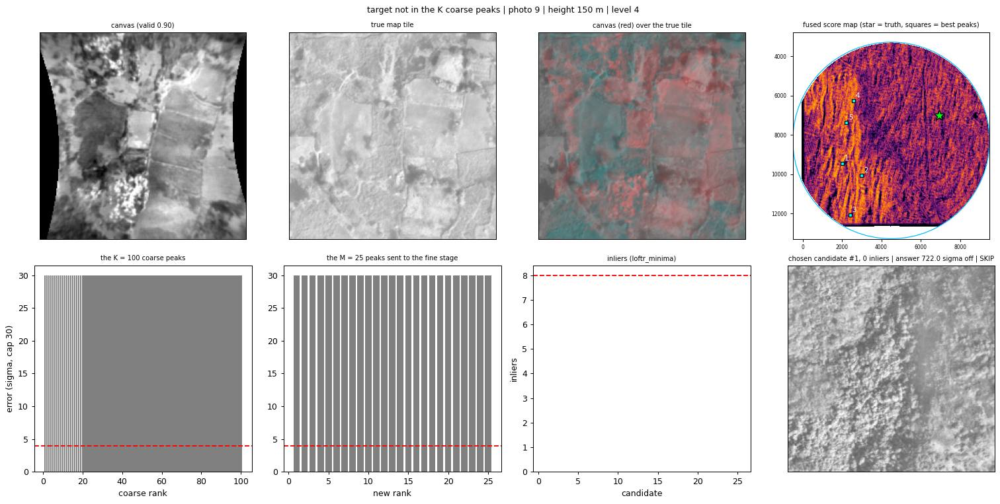

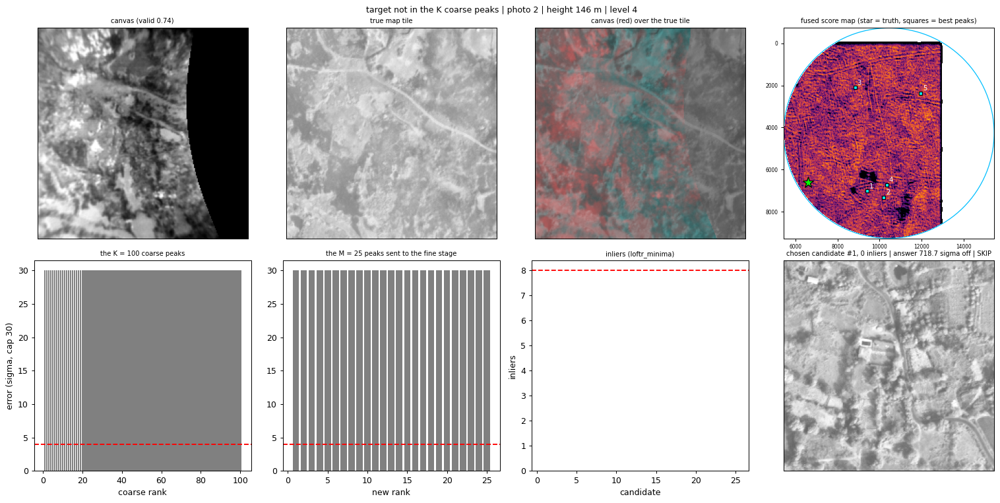

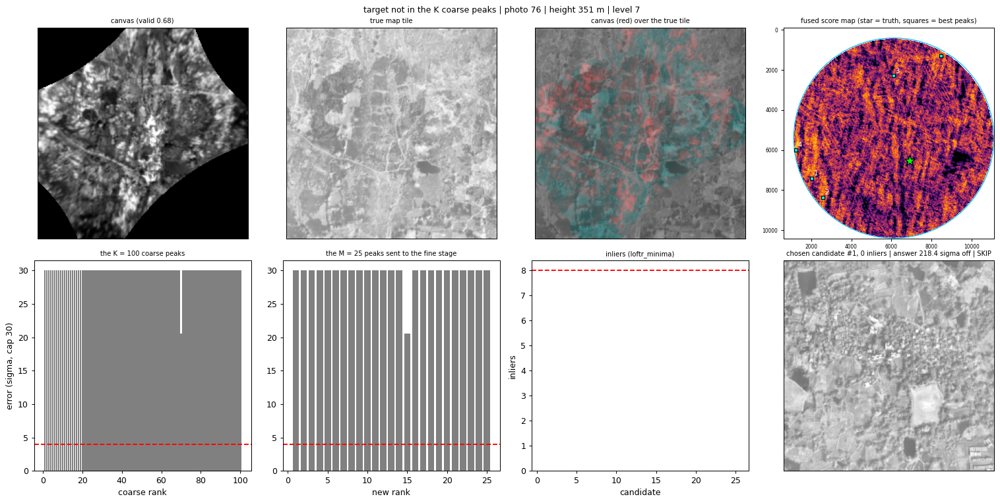

target in K but not in the M sent to fine: 0 photos
target in M but the wrong candidate was chosen: 1 photos


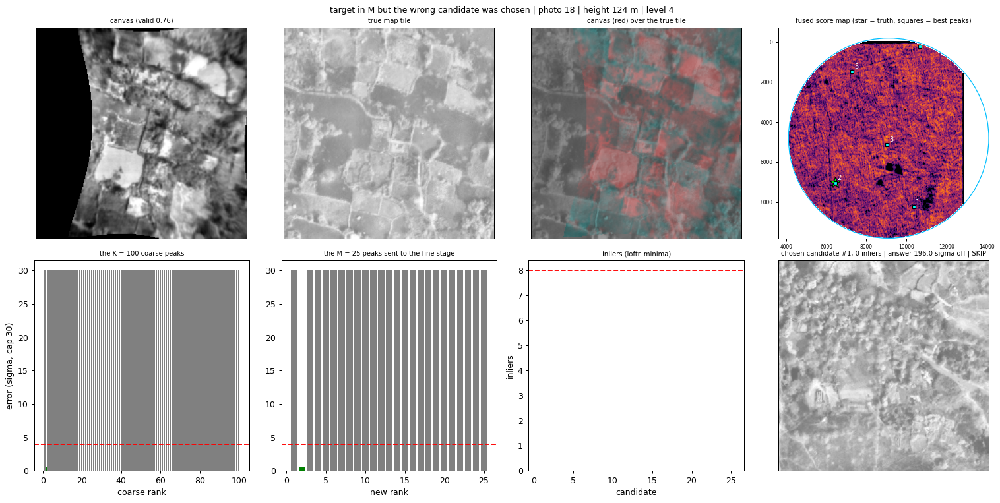

right candidate chosen but skipped (too few inliers): 9 photos


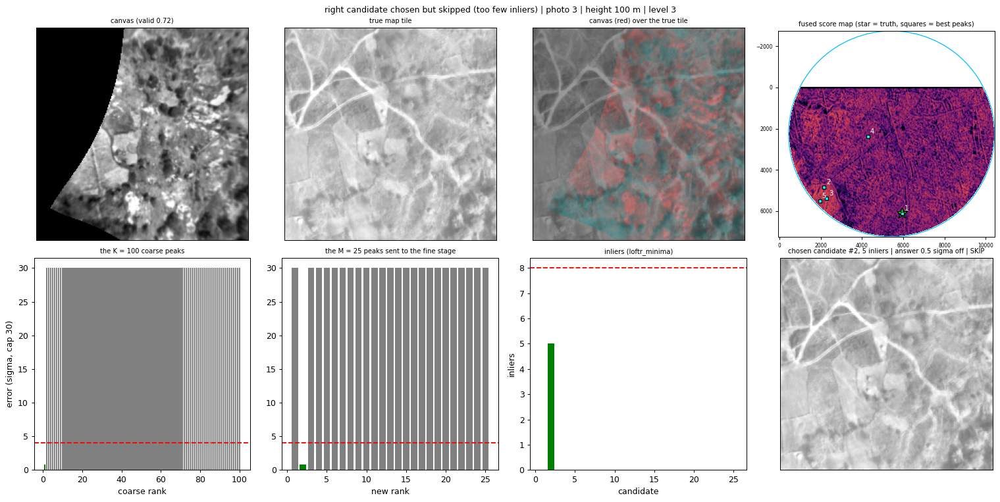

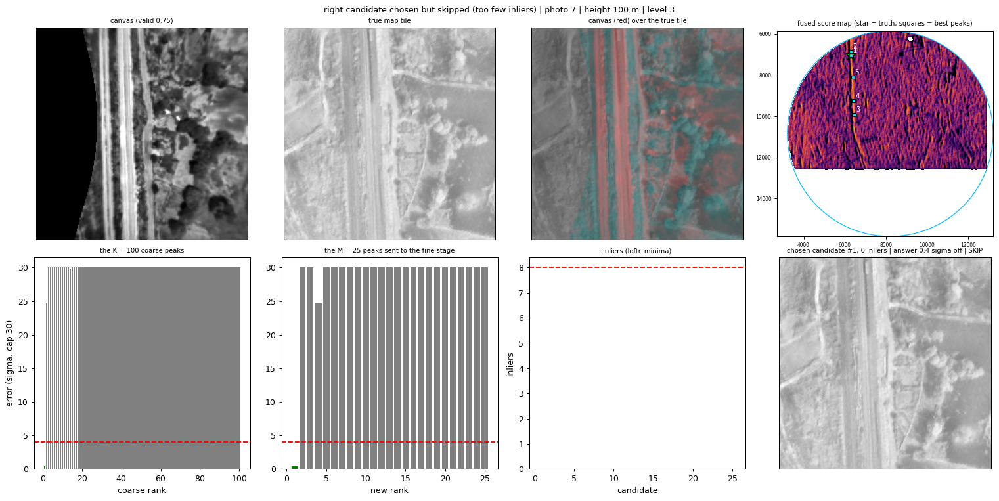

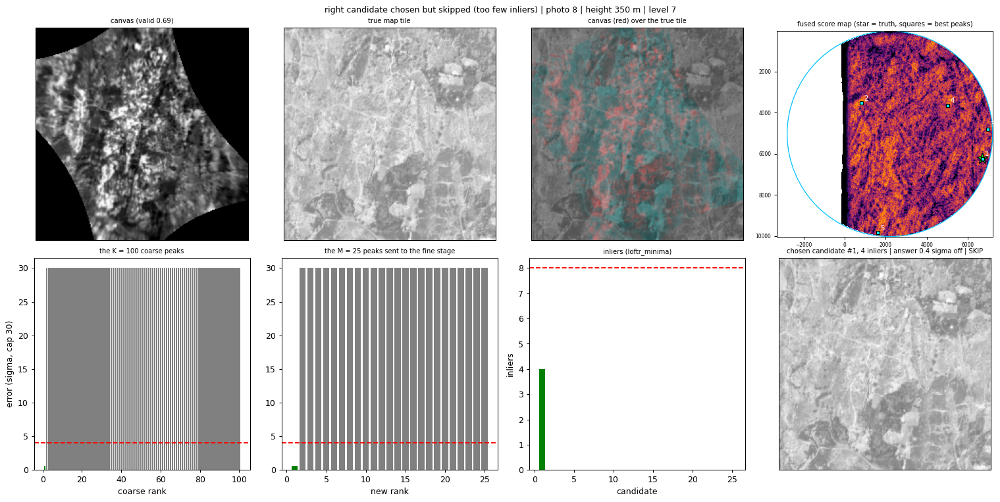

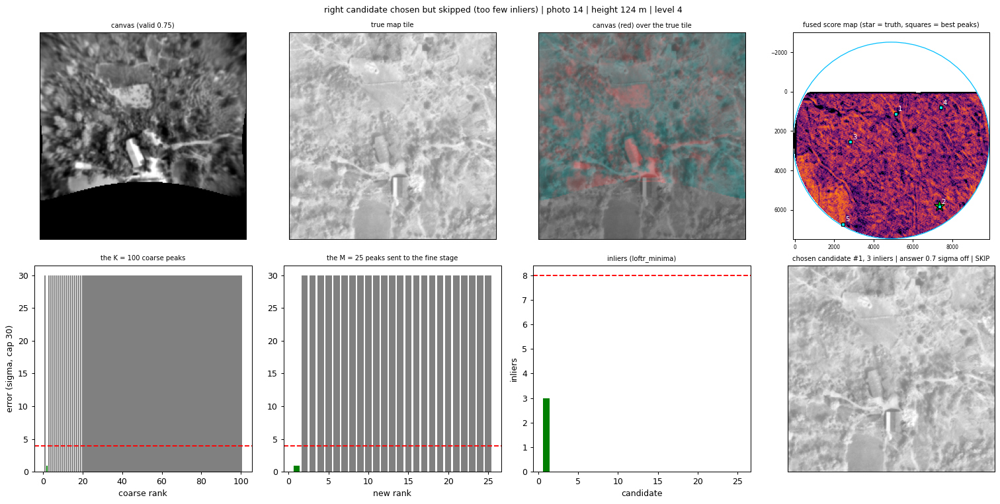

answered, but wrong place: 0 photos
good: answered within 1 sigma: 46 photos


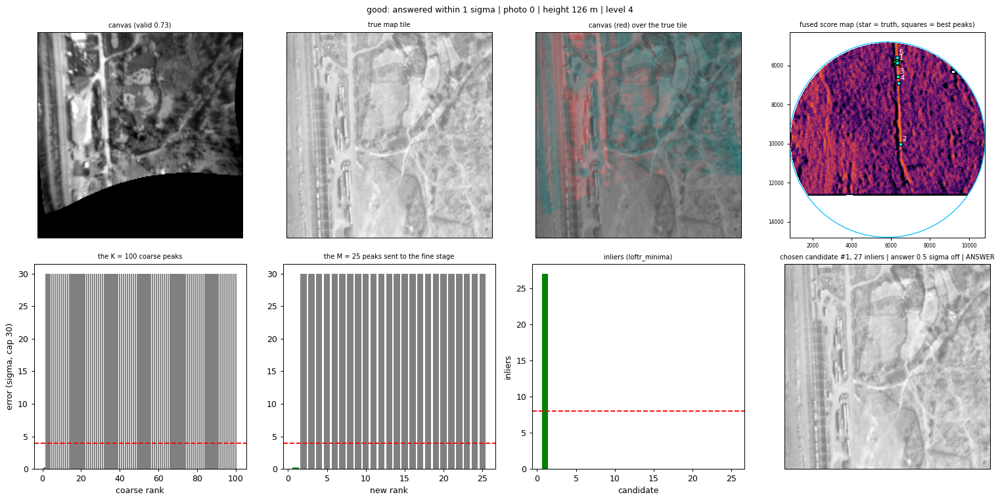

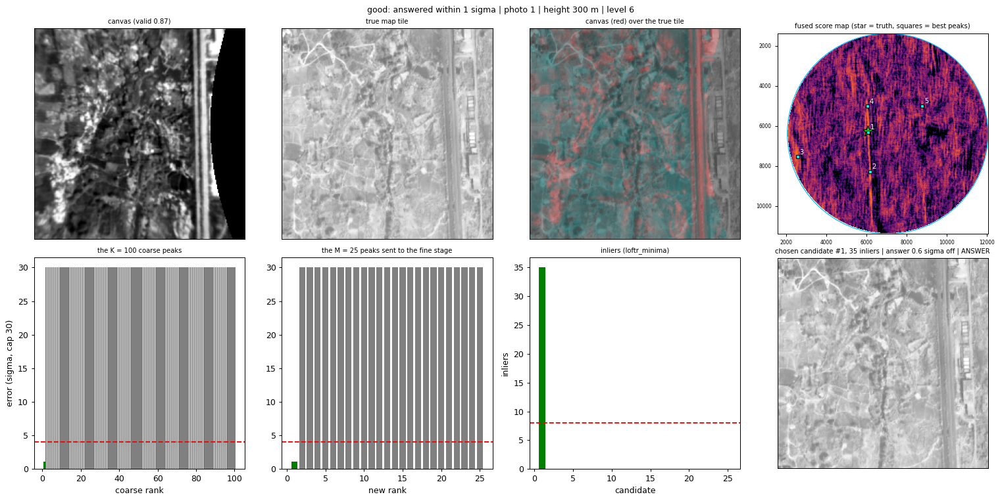

In [ ]:
def draw_heat_map(axis, score_map, geometry, peaks, index, how_many=5):
    record = record_by_index[index]
    heat = score_map.cpu().numpy().copy()
    inside = geometry["inside"].cpu().numpy()
    heat[~inside | (heat <= -1)] = np.nan
    x_m = geometry["x_m"].cpu().numpy()
    y_m = geometry["y_m"].cpu().numpy()
    axis.imshow(heat, cmap="inferno", vmin=np.nanpercentile(heat, 5), vmax=np.nanmax(heat), extent=(x_m[0], x_m[-1], y_m[-1], y_m[0]))
    axis.add_patch(plt.Circle(test_set.priors[index], settings.DISC_RADIUS, fill=False, color="deepskyblue", lw=1.0))
    axis.plot(record["truth"][0], record["truth"][1], "*", color="lime", markersize=14, markeredgecolor="black")
    for rank in range(min(how_many, len(peaks))):
        if peaks[rank, 1] < 1e8:
            axis.plot(peaks[rank, 1], peaks[rank, 2], "s", color="cyan", markersize=4, markeredgecolor="black")
            axis.annotate(str(rank + 1), (peaks[rank, 1], peaks[rank, 2]), color="white", fontsize=8, xytext=(3, 3), textcoords="offset points")
    axis.set_title("%s score map (star = truth, squares = best peaks)" % PRIMARY, fontsize=8)
    axis.tick_params(labelsize=6)


def draw_sample(index, label):
    record = record_by_index[index]
    row, details = answer_for(record, fine[MATCHERS[0]][index], BASE)
    data = record["methods"][PRIMARY]
    truth = record["truth"]
    level = record["level"]
    true_tile = map_piece(level_images, level, truth[0], truth[1])
    blend = np.stack([true_tile, true_tile, true_tile], axis=-1) * 0.6
    blend[..., 0] = np.where(record["valid"], 0.5 * blend[..., 0] + 0.5 * record["canvas"], blend[..., 0])

    inputs = make_inputs(record["canvas"], record["valid"], level, test_set.priors[index], pipeline.families, pipeline.names)
    score_map = METHODS[PRIMARY](inputs)

    fig = plt.figure(figsize=(17, 8.6))
    grid = fig.add_gridspec(2, 4)
    show(fig.add_subplot(grid[0, 0]), record["canvas"] * record["valid"], "canvas (valid %.2f)" % record["valid_frac"])
    show(fig.add_subplot(grid[0, 1]), true_tile, "true map tile")
    show(fig.add_subplot(grid[0, 2]), np.clip(blend, 0, 1), "canvas (red) over the true tile")
    draw_heat_map(fig.add_subplot(grid[0, 3]), score_map, inputs["geometry"], data["short"], index)

    coarse_errors = data["err"][:BASE["K"]]
    axis = fig.add_subplot(grid[1, 0])
    axis.bar(range(1, len(coarse_errors) + 1), np.minimum(coarse_errors, 30), color=["green" if e <= FOUND_SIGMA else "gray" for e in coarse_errors])
    axis.axhline(FOUND_SIGMA, color="red", ls="--")
    axis.set_xlabel("coarse rank")
    axis.set_ylabel("error (sigma, cap 30)")
    axis.set_title("the K = %d coarse peaks" % BASE["K"], fontsize=8)

    axis = fig.add_subplot(grid[1, 1])
    axis.bar(range(1, len(details["errors"]) + 1), np.minimum(details["errors"], 30), color=["green" if e <= FOUND_SIGMA else "gray" for e in details["errors"]])
    axis.axhline(FOUND_SIGMA, color="red", ls="--")
    axis.set_xlabel("new rank")
    axis.set_title("the M = %d peaks sent to the fine stage" % BASE["M"], fontsize=8)

    inliers = fine[MATCHERS[0]][index]["inliers"][details["order"]]
    axis = fig.add_subplot(grid[1, 2])
    axis.bar(range(1, len(inliers) + 1), inliers, color=["green" if e <= FOUND_SIGMA else "gray" for e in details["errors"]])
    axis.axhline(BASE["bar"], color="red", ls="--")
    axis.set_xlabel("candidate")
    axis.set_ylabel("inliers")
    axis.set_title("inliers (%s)" % MATCHERS[0], fontsize=8)

    chosen_peak = data["short"][details["order"][details["chosen"]]]
    show(fig.add_subplot(grid[1, 3]), map_piece(level_images, level, chosen_peak[1], chosen_peak[2]),
         "chosen candidate #%d, %d inliers | answer %.1f sigma off | %s" % (details["chosen"] + 1, row["inliers"], row["err_sigma"], "ANSWER" if row["answered"] else "SKIP"))
    fig.suptitle("%s | photo %d | height %.0f m | level %d" % (label, index, record["height"], level), fontsize=10)
    plt.tight_layout()
    plt.show()
    del inputs
    if DEVICE == "cuda":
        torch.cuda.empty_cache()


table = base[MATCHERS[0]]
kinds = [
    ("target not in the K coarse peaks", table[~table["in_K"]].sort_values("err_sigma", ascending=False)),
    ("target in K but not in the M sent to fine", table[table["in_K"] & ~table["in_M"]]),
    ("target in M but the wrong candidate was chosen", table[table["in_M"] & ~table["chosen_right"]]),
    ("right candidate chosen but skipped (too few inliers)", table[table["chosen_right"] & ~table["answered"]]),
    ("answered, but wrong place", table[table["answered"] & (table["err_sigma"] > FOUND_SIGMA)]),
    ("good: answered within 1 sigma", table[table["answered"] & (table["err_sigma"] <= STRICT_SIGMA)]),
]
for label, part in kinds:
    print("=" * 100)
    print("%s: %d photos" % (label, len(part)))
    count_shown = N_SAMPLES if not label.startswith("good") else min(2, N_SAMPLES)
    for photo in list(part["photo"])[:count_shown]:
        draw_sample(int(photo), label)

# Part 10 · Save the tables

The per-photo table of the baseline (one row per photo and matcher) and the sweep tables go to `tests/Stage_Evaluation/`, so settings can be compared later without running anything again.

In [ ]:
out_dir = ROOT / "tests" / "Stage_Evaluation"
out_dir.mkdir(parents=True, exist_ok=True)
tag = "%s_%s_K%d_M%d" % (DATA if DATA == "official" else "nudt-" + NUDT_SPLIT, PRIMARY, K_BASE, M_BASE)

for name in MATCHERS:
    table = base[name].copy()
    table["height"] = [record_by_index[p]["height"] for p in table["photo"]]
    table["valid_frac"] = [record_by_index[p]["valid_frac"] for p in table["photo"]]
    table["contrast"] = [record_by_index[p]["contrast"] for p in table["photo"]]
    table["edge_strength"] = [record_by_index[p]["edge_strength"] for p in table["photo"]]
    table["near_z"] = [record_by_index[p]["methods"][PRIMARY]["stats"]["near_z"] for p in table["photo"]]
    table["map_max_err_sigma"] = [record_by_index[p]["methods"][PRIMARY]["stats"]["argmax_err"] for p in table["photo"]]
    table.to_csv(out_dir / ("per_photo_%s_%s.csv" % (tag, name)), index=False)
    print("saved", out_dir / ("per_photo_%s_%s.csv" % (tag, name)))

sweep_kmw.to_csv(out_dir / ("sweep_K_M_weight_%s_%s.csv" % (tag, MATCHERS[0])), index=False)
sweep_bar.to_csv(out_dir / ("sweep_bar_gamma_rescue_%s.csv" % tag), index=False)
map_table.to_csv(out_dir / ("maps_%s.csv" % tag), index=False)
print("saved the sweep tables and the map table in", out_dir)

# one line per run in tests/Stage_Evaluation/runs_summary.csv: the settings that change the data (map, coarse method, matcher, ...) and the result.
# Run the notebook again with another MAP / COARSE / MATCHERS / MAP_MARGIN_M and Part 10 compares the runs.
run = dict(data=DATA, split=NUDT_SPLIT if DATA == "nudt" else "-", map=pipeline.satellite if DATA == "official" else "nudt", map_margin_m=str(pipeline.map_margin_m), coarse=PRIMARY, matcher=MATCHERS[0],
           n_eval=len(records), seed=SEED, K=K_BASE, M=M_BASE, layer=USE_SEMANTIC_LAYER, weight=WEIGHT_BASE, gamma=GAMMA,
           rescue=str(BASE["rescue"]), bar=BASE["bar"], ransac_px=pipeline.ransac_pixels, confidence=MATCHER_CONFIDENCE)
run.update(summarise(base[MATCHERS[0]]))
registry_file = out_dir / "runs_summary.csv"
new_run = pd.DataFrame([run])
if registry_file.exists():
    registry = pd.read_csv(registry_file)
    setting_columns = [c for c in new_run.columns if c not in summarise(base[MATCHERS[0]])]
    registry = registry.astype(str)
    same = registry[setting_columns].eq(new_run[setting_columns].astype(str).iloc[0]).all(axis=1)
    registry = pd.concat([registry[~same], new_run.astype(str)], ignore_index=True)
else:
    registry = new_run.astype(str)
registry.to_csv(registry_file, index=False)
print("this run added to", registry_file, "(%d runs stored)" % len(registry))


saved /home/voidness/Storage/Synced Folders/InterIIT Tech 15/IdeaForge-GeoLoc-InterIIT15/tests/Stage_Evaluation/per_photo_official_fused_K100_M25_loftr_minima.csv
saved the sweep tables and the map table in /home/voidness/Storage/Synced Folders/InterIIT Tech 15/IdeaForge-GeoLoc-InterIIT15/tests/Stage_Evaluation
this run added to /home/voidness/Storage/Synced Folders/InterIIT Tech 15/IdeaForge-GeoLoc-InterIIT15/tests/Stage_Evaluation/runs_summary.csv (1 runs stored)


# Part 10 · Compare runs: the hyperparameters that change the data

The map, the margin around the photos, the coarse method, the fine matcher and the number of photos cannot be re-scored from stored numbers: each needs its own run of this notebook (change the setting at the top, run all). Every run adds one line to `tests/Stage_Evaluation/runs_summary.csv`; this part reads that file. Compare only runs that share `n_eval` and `seed` (the same photos), and keep in mind that the whole table is a noisy estimate (the two halves show how noisy).

For each such hyperparameter the chart shows the best score per value of that hyperparameter among the stored runs.

In [ ]:
runs = pd.read_csv(out_dir / "runs_summary.csv")
for column in ["score (/60)", "first half", "second half", "answered", "target in K", "target in M", "top-1 ok", "wrong answers"]:
    runs[column] = runs[column].astype(float)
shown = ["data", "map", "map_margin_m", "coarse", "matcher", "n_eval", "seed", "K", "M", "bar", "score (/60)", "first half", "second half", "answered", "target in K", "wrong answers"]
print("all stored runs, best score first:")
display(runs.sort_values("score (/60)", ascending=False)[shown].round(3).reset_index(drop=True))

rebuild = ["map", "map_margin_m", "coarse", "matcher", "n_eval"]
varying = [name for name in rebuild if runs[name].nunique() > 1]
if len(varying) == 0:
    print("every stored run has the same map, margin, coarse method, matcher and n_eval: run the notebook again with another setting to compare.")
else:
    fig, axes = plt.subplots(1, len(varying), figsize=(5.2 * len(varying), 3.8), squeeze=False)
    for axis, name in zip(axes[0], varying):
        best = runs.groupby(name)["score (/60)"].max().sort_values(ascending=False)
        counts = runs.groupby(name).size().reindex(best.index)
        axis.bar([str(v) for v in best.index], best.values, color="tab:blue")
        for position, (value, count) in enumerate(zip(best.values, counts.values)):
            axis.text(position, value, "%.1f\n(%d runs)" % (value, count), ha="center", va="bottom", fontsize=8)
        axis.set_ylabel("best score (/60)")
        axis.set_xlabel(name)
        axis.set_ylim(0, 60)
        axis.set_title("best score by %s" % name, fontsize=9)
    plt.tight_layout()
    plt.show()


all stored runs, best score first:


,data,map,map_margin_m,coarse,matcher,n_eval,seed,K,M,bar,score (/60),first half,second half,answered,target in K,wrong answers
0,official,new,None,fused,loftr_minima,66,450,100,25,8,43.455,37.455,49.455,0.742,0.894,0.0


every stored run has the same map, margin, coarse method, matcher and n_eval: run the notebook again with another setting to compare.


# Part 11 · The strategies from the analysis, tested

A written analysis of the first 100-photo run proposed eight strategies (S1 to S8). Each is a rule or a setting that can be scored on the stored numbers, so each is tested here with the same tools as Part 8, plus two things Part 8 lacks:

* a **paired bootstrap** (the same photos, with and without the change): the gain in points out of 60 with a 95 % interval;
* an **out-of-sample check** (11.2): choose the rule on one half of the photos and score it on the other half. A rule picked and scored on the same 100 photos is optimistic, and the zero-inlier rescue (S2) was picked that way.

| | idea | where |
|---|---|---|
| S1 | lower the answer bar (to 3) | 11.1 |
| S2 | answer the first place when it has 0 inliers and DINO is sure (z at least 3) | 11.1, 11.2, 11.3 |
| S3 | the right photos with 0 inliers that S2 cannot rescue (second matcher?) | 11.4 |
| S4 | send fewer candidates (M = 5 to 10) to the fine stage | 11.1 |
| S5 | the photos lost at the coarse stage (K up to 200, edge ZNCC alone) | 11.1, 11.5 |
| S6 | allow the fine stage to override the first place or not | 11.6 |
| S7 | does the error grow with height (bias)? | 11.7 |
| S8 | what not to spend time on: nothing to test | |

S5 needs `K_MAX = 200` in the settings (pass B then runs about 4 times longer) and, for the edge-only comparison, a second run with `COARSE = "edge_zncc"` (Part 10 compares the runs). Held-out photos need a second run with another `FIRST_PHOTO`.

## 11.1 The rules side by side, with a paired bootstrap against the baseline

In [ ]:
def paired_gain(points_new, points_old, resamples=4000):
    """Gain in score (out of 60) of the new points over the old points on the same photos, with a bootstrap 95 % interval.
    The score is 6 x the mean points per photo (final_score: 60 x sum / (10 x photos))."""
    difference = np.asarray(points_new, dtype=float) - np.asarray(points_old, dtype=float)
    assert len(difference) > 1, "need at least two photos"
    generator = np.random.default_rng(SEED)
    picks = generator.integers(0, len(difference), size=(resamples, len(difference)))
    means = 6.0 * difference[picks].mean(axis=1)
    return 6.0 * difference.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5)


ZERO_RESCUE = (0, 3.0)
STRATEGIES = {
    "baseline (settings above)": BASE,
    "S1  bar 3": dict(BASE, bar=3),
    "S2  bar 3 + zero-inlier rescue z >= 3.0": dict(BASE, bar=3, rescue=(0, 3.0), layer=True),
    "S2  ... z >= 2.5": dict(BASE, bar=3, rescue=(0, 2.5), layer=True),
    "S2  ... z >= 2.0": dict(BASE, bar=3, rescue=(0, 2.0), layer=True),
    "S2  ... z >= 3.5": dict(BASE, bar=3, rescue=(0, 3.5), layer=True),
    "S4  S2 with M = 5, DINO weight 3": dict(BASE, bar=3, rescue=(0, 3.0), layer=True, M=5, weight=3.0),
    "S4  S2 with M = 5, DINO weight 10": dict(BASE, bar=3, rescue=(0, 3.0), layer=True, M=5, weight=10.0),
    "S4  S2 with M = 10, DINO weight 3": dict(BASE, bar=3, rescue=(0, 3.0), layer=True, M=10, weight=3.0),
    "S5  S2 with K = 100": dict(BASE, bar=3, rescue=(0, 3.0), layer=True, K=100),
    "S5  S2 with K = 200": dict(BASE, bar=3, rescue=(0, 3.0), layer=True, K=200),
}
STRATEGIES = {name: cfg for name, cfg in STRATEGIES.items() if cfg["K"] <= K_MAX and cfg["M"] <= cfg["K"]}
strategy_tables = {name: evaluate(cfg, MATCHERS[0]) for name, cfg in STRATEGIES.items()}
reference = strategy_tables["baseline (settings above)"]
rows = []
for name, table in strategy_tables.items():
    row = {"rule": name}
    row.update({key: value for key, value in summarise(table).items() if key in ("score (/60)", "first half", "second half", "answered", "wrong answers", "right but skipped")})
    gain, low, high = paired_gain(table["points"], reference["points"])
    row["gain vs baseline"] = gain
    row["95% low"] = low
    row["95% high"] = high
    rows.append(row)
display(pd.DataFrame(rows).round(2))
print("a gain whose interval includes 0 is not shown by these photos; a rule that wins in one half only is noise")
if K_MAX < 200:
    print("S5 rows with K = 100 / 200 are missing: set K_MAX = 200 in the settings and run again (pass B takes about 4 times longer).")

,rule,score (/60),first half,second half,answered,wrong answers,right but skipped,gain vs baseline,95% low,95% high
0,baseline (settings above),43.45,37.45,49.45,0.74,0,9,0.00,0.00,0.00
1,S1 bar 3,49.09,46.91,51.27,0.85,0,2,5.64,2.00,9.82
2,S2 bar 3 + zero-inlier rescue z >= 3.0,49.09,46.91,51.27,0.85,0,2,5.64,2.00,9.82
3,S2 ... z >= 2.5,44.55,37.82,51.27,0.91,3,1,1.09,-7.09,8.36
4,S2 ... z >= 2.0,43.64,34.18,53.09,0.94,4,0,0.18,-8.91,8.55
5,S2 ... z >= 3.5,49.09,46.91,51.27,0.85,0,2,5.64,2.00,9.82
6,"S4 S2 with M = 5, DINO weight 3",49.09,46.91,51.27,0.85,0,3,5.64,2.00,9.82
7,"S4 S2 with M = 5, DINO weight 10",49.09,46.91,51.27,0.85,0,2,5.64,2.00,9.82
8,"S4 S2 with M = 10, DINO weight 3",49.09,46.91,51.27,0.85,0,3,5.64,2.00,9.82
9,S5 S2 with K = 100,49.09,46.91,51.27,0.85,0,2,5.64,2.00,9.82


a gain whose interval includes 0 is not shown by these photos; a rule that wins in one half only is noise
S5 rows with K = 100 / 200 are missing: set K_MAX = 200 in the settings and run again (pass B takes about 4 times longer).


## 11.2 Out-of-sample check: choose on one half, score on the other

A grid of answer bars and zero-inlier cuts. For each half of the photos, the best rule of the grid is chosen on that half only and then scored on the other half; the second row of each pair is the baseline on the same held-out half. If the chosen rule does not beat the baseline on the half it was not chosen on, the in-sample gain of 11.1 is mostly picking noise.

In [ ]:
def half_score(table, which):
    half = len(table) // 2
    part = table.iloc[:half] if which == 0 else table.iloc[half:]
    return final_score(list(part["points"])), int((part["points"] < 0).sum()), len(part)


grid_bars = [b for b in (1, 2, 3, 4, 6, 8, 10, 13, 16)]
grid_cuts = [None, 2.0, 2.5, 3.0, 3.5, 4.0]
grid = []
for bar in grid_bars:
    for cut in grid_cuts:
        cfg = dict(BASE, bar=bar, rescue=None if cut is None else (0, cut), layer=True)
        grid.append((bar, cut, evaluate(cfg, MATCHERS[0])))

rows = []
for choose_on in (0, 1):
    test_on = 1 - choose_on
    ranked = sorted(grid, key=lambda g: (half_score(g[2], choose_on)[0], -half_score(g[2], choose_on)[1], g[0], -(g[1] or 0)), reverse=True)
    bar, cut, table = ranked[0]
    base_score = half_score(reference, test_on)[0]
    rows.append({"chosen on": "half %d" % (choose_on + 1), "rule": "bar %d, rescue %s" % (bar, "none" if cut is None else "(0, %.1f)" % cut),
                 "score on the half it was chosen on": half_score(table, choose_on)[0], "score on the other half": half_score(table, test_on)[0],
                 "baseline on the other half": base_score, "gain on the other half": half_score(table, test_on)[0] - base_score,
                 "wrong answers on the other half": half_score(table, test_on)[1]})
display(pd.DataFrame(rows).round(2))
print("grid: bars %s x zero-inlier z cuts %s (None = no zero-inlier rescue)" % (grid_bars, grid_cuts))

,chosen on,rule,score on the half it was chosen on,score on the other half,baseline on the other half,gain on the other half,wrong answers on the other half
0,half 1,"bar 4, rescue (0, 3.0)",46.91,51.27,49.45,1.82,0
1,half 2,"bar 8, rescue (0, 2.0)",53.09,32.36,37.45,-5.09,4


grid: bars [1, 2, 3, 4, 6, 8, 10, 13, 16] x zero-inlier z cuts [None, 2.0, 2.5, 3.0, 3.5, 4.0] (None = no zero-inlier rescue)


## 11.3 S2: why a z cut of 3, and how sure are we?

The photos whose first place has no inliers, split by whether that first place is right. The grey histogram is what the best of K standardised DINO scores looks like when DINO knows nothing (simulated): a z of 3 is reached by chance in a few percent of photos, 2.5 in about a fifth. A cut is only safe where right photos stand clear of that chance band.

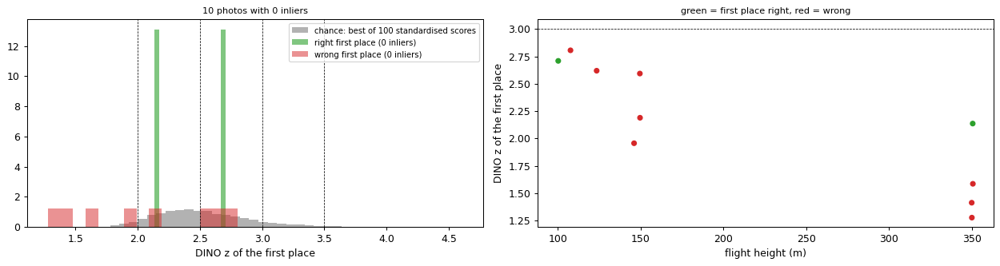

,z cut,photos rescued,right,wrong,share right,lower bound (95 %),chance of reaching it (simulated)
0,2.0,6,2,4,0.333,0.097,0.950
1,2.5,4,1,3,0.250,0.046,0.475
2,3.0,0,0,0,NaN,NaN,0.109
3,3.5,0,0,0,NaN,NaN,0.016
4,4.0,0,0,0,NaN,NaN,0.002


break-even: an answer is worth about +9 if right and -20 if wrong, so a rescue pays only when more than about 69 % of the rescued photos are right; the lower bound shows what the photos prove


In [ ]:
zero_cfg = dict(BASE, bar=3, rescue=None, layer=True)
zero_table = evaluate(zero_cfg, MATCHERS[0])
zero = zero_table[zero_table["inliers"] == 0].copy()
zero["right"] = zero["err_sigma"] <= FOUND_SIGMA
generator = np.random.default_rng(SEED)
chance = generator.standard_normal((20000, BASE["K"]))
chance = ((chance - chance.mean(axis=1, keepdims=True)) / chance.std(axis=1, keepdims=True)).max(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].hist(chance, bins=40, color="tab:gray", alpha=0.6, density=True, label="chance: best of %d standardised scores" % BASE["K"])
axes[0].hist(zero.loc[zero["right"], "z_chosen"], bins=15, color="tab:green", alpha=0.6, density=True, label="right first place (0 inliers)")
axes[0].hist(zero.loc[~zero["right"], "z_chosen"], bins=15, color="tab:red", alpha=0.5, density=True, label="wrong first place (0 inliers)")
for cut in (2.0, 2.5, 3.0, 3.5):
    axes[0].axvline(cut, color="black", lw=0.6, ls="--")
axes[0].set_xlabel("DINO z of the first place")
axes[0].legend(fontsize=8)
axes[0].set_title("%d photos with 0 inliers" % len(zero), fontsize=9)
axes[1].scatter(zero["height"], zero["z_chosen"], c=["tab:green" if r else "tab:red" for r in zero["right"]], s=22)
axes[1].axhline(3.0, color="black", lw=0.6, ls="--")
axes[1].set_xlabel("flight height (m)")
axes[1].set_ylabel("DINO z of the first place")
axes[1].set_title("green = first place right, red = wrong", fontsize=9)
plt.tight_layout()
plt.show()

rows = []
for cut in (2.0, 2.5, 3.0, 3.5, 4.0):
    chosen = zero[zero["z_chosen"] >= cut]
    right = int(chosen["right"].sum())
    n = len(chosen)
    if n > 0:                                                             # Wilson 95 % lower bound of the share right
        p = right / n
        z95 = 1.96
        low = (p + z95 ** 2 / (2 * n) - z95 * math.sqrt(p * (1 - p) / n + z95 ** 2 / (4 * n * n))) / (1 + z95 ** 2 / n)
    else:
        low = np.nan
    rows.append({"z cut": cut, "photos rescued": n, "right": right, "wrong": n - right, "share right": right / n if n > 0 else np.nan,
                 "lower bound (95 %)": low, "chance of reaching it (simulated)": float((chance >= cut).mean())})
display(pd.DataFrame(rows).round(3))
print("break-even: an answer is worth about +9 if right and -20 if wrong, so a rescue pays only when more than about 69 % of the rescued photos are right; the lower bound shows what the photos prove")

## 11.4 S3: right photos that are still skipped after S2

Photos whose right place is in the candidates but which stay skipped under the S2 rule (bar 3, zero-inlier rescue at z 3). If `MATCHERS` holds more than one matcher, the last columns show the inliers each of them found on the right candidate: a matcher that finds inliers where the first one found none is the kind of second opinion S3 asks for.

In [ ]:
s2_cfg = dict(BASE, bar=3, rescue=(0, 3.0), layer=True)
s2_table = evaluate(s2_cfg, MATCHERS[0])
lost = s2_table[(~s2_table["answered"]) & s2_table["in_M"]]
rows = []
for _, row in lost.iterrows():
    record = record_by_index[int(row["photo"])]
    order, errors = ordered_errors(record, PRIMARY, s2_cfg["K"], s2_cfg["M"], s2_cfg["layer"], s2_cfg["weight"])
    right = errors <= FOUND_SIGMA
    entry = {"photo": int(row["photo"]), "height": record["height"], "valid share": record["valid_frac"], "DINO z (first place)": row["z_chosen"]}
    for name in MATCHERS:
        entry["inliers, %s" % name] = fine[name][record["index"]]["inliers"][order][right].max() if right.any() else np.nan
    rows.append(entry)
print("%d photos have the right place among the M candidates but stay skipped under S2 (the points they could still earn: about +%.1f /60)" % (
    len(rows), 6 * 10 * len(rows) / len(s2_table) / 10 if len(s2_table) > 0 else 0))
if len(rows) > 0:
    display(pd.DataFrame(rows).sort_values("height").round(2).reset_index(drop=True))

3 photos have the right place among the M candidates but stay skipped under S2 (the points they could still earn: about +0.3 /60)


,photo,height,valid share,DINO z (first place),"inliers, loftr_minima"
0,7,100.3,0.75,2.71,0.0
1,18,123.5,0.76,2.62,0.0
2,63,350.6,0.68,2.14,0.0


## 11.5 S5: the photos lost at the coarse stage

The photos where no peak within `FOUND_SIGMA` of the truth is among the first K. For each: how high the flight was, how much of the canvas is valid, how visible the target is in the score map (`near_z`), and at which rank the first right peak appears if it is among the `K_MAX` peaks at all. The curve shows how the share of found photos grows with K: if it is still rising at `K_MAX`, a larger K (with DINO as the judge) is worth trying.

photos with no right place in the first K = 100 peaks: 7 of 66


,photo,height,valid share,near_z,first right rank (of K_MAX)
0,12,107.7,0.76,2.27,NaN
1,2,146.1,0.74,2.23,NaN
2,30,149.6,0.90,2.80,NaN
3,9,149.7,0.90,1.97,NaN
4,55,350.0,0.72,2.12,NaN
5,97,350.1,0.65,1.88,NaN
6,76,350.7,0.68,2.20,NaN


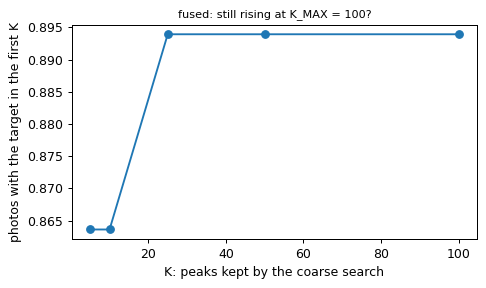

In [ ]:
rows = []
for record in records:
    errors = record["methods"][PRIMARY]["err"]
    right_ranks = np.where(errors[:K_MAX] <= FOUND_SIGMA)[0]
    if not (errors[:K_BASE] <= FOUND_SIGMA).any():
        rows.append({"photo": record["index"], "height": record["height"], "valid share": record["valid_frac"],
                     "near_z": record["methods"][PRIMARY]["stats"]["near_z"],
                     "first right rank (of K_MAX)": int(right_ranks[0]) + 1 if len(right_ranks) > 0 else np.nan})
print("photos with no right place in the first K = %d peaks: %d of %d" % (K_BASE, len(rows), len(records)))
if len(rows) > 0:
    display(pd.DataFrame(rows).sort_values("height").round(2).reset_index(drop=True))

ks = [k for k in (5, 10, 25, 50, 100, 150, 200) if k <= K_MAX]
curve = [np.mean([(r["methods"][PRIMARY]["err"][:k] <= FOUND_SIGMA).any() for r in records]) for k in ks]
fig, axis = plt.subplots(figsize=(5.5, 3.3))
axis.plot(ks, curve, "o-")
axis.set_xlabel("K: peaks kept by the coarse search")
axis.set_ylabel("photos with the target in the first K")
axis.set_title("%s: still rising at K_MAX = %d?" % (PRIMARY, K_MAX), fontsize=9)
plt.tight_layout()
plt.show()

## 11.6 S6: overrides, the fine stage choosing another place than the first

Under the baseline, for how many photos does the fine stage choose a candidate other than the first one (after the DINO order), and were those answers right? The gate row scores the rule "answer only when the chosen place is the first one": it costs the points of the right overrides and protects against the wrong ones.

In [ ]:
gate_table = evaluate(s2_cfg, MATCHERS[0])
overrides = gate_table[gate_table["answered"] & (~gate_table["top_first"])]
print("answered photos where the chosen place is not the first one: %d (right within %.0f sigma: %d, wrong: %d)" % (
    len(overrides), FOUND_SIGMA, int((overrides["err_sigma"] <= FOUND_SIGMA).sum()), int((overrides["err_sigma"] > FOUND_SIGMA).sum())))
gated_points = gate_table["points"].where(gate_table["top_first"] | (~gate_table["answered"]), 0)
rows = [{"rule": "answer whatever the fine stage chose (S2)", "score (/60)": final_score(list(gate_table["points"])), "answered": gate_table["answered"].mean()},
        {"rule": "answer only when the chosen place is the first one", "score (/60)": final_score(list(gated_points)),
         "answered": (gate_table["answered"] & gate_table["top_first"]).mean()}]
display(pd.DataFrame(rows).round(3))
if len(overrides) > 0:
    display(overrides[["photo", "height", "chosen_rank", "inliers", "z_chosen", "err_sigma", "points"]].round(2).reset_index(drop=True))

answered photos where the chosen place is not the first one: 2 (right within 4 sigma: 2, wrong: 0)


,rule,score (/60),answered
0,answer whatever the fine stage chose (S2),49.091,0.848
1,answer only when the chosen place is the first...,47.273,0.818


,photo,height,chosen_rank,inliers,z_chosen,err_sigma,points
0,3,100.1,0,5.0,1.69,0.53,10
1,6,109.4,0,8.0,1.25,0.55,10


## 11.7 S7: does the error grow with the height of the flight?

The signed east and north errors of the answered photos against the height. A slope of the unsigned error with height, or a mean signed error that is not near zero, would be a bias that a correction could remove. The range of heights here is only 100 to 350 m; whatever is read from it about 1000 m or more is an extrapolation.

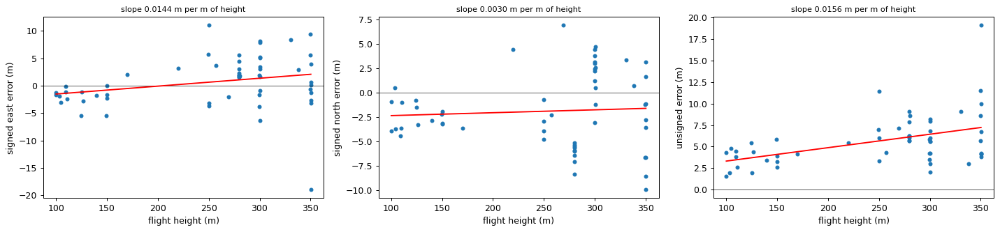

answered photos: 56 | mean signed error: east +0.66 m, north -1.93 m | median unsigned error 5.53 m
slope of the unsigned error with height: 0.0156 m per m, 95 % interval 0.0080 to 0.0246 (an interval that excludes 0 is a growing error)


In [ ]:
answered = gate_table[gate_table["answered"]]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for axis, column, label in ((axes[0], "dx_m", "signed east error (m)"), (axes[1], "dy_m", "signed north error (m)"), (axes[2], "err_m", "unsigned error (m)")):
    axis.scatter(answered["height"], answered[column], s=14)
    axis.axhline(0, color="black", lw=0.5)
    slope, intercept = np.polyfit(answered["height"], answered[column], 1)
    heights_line = np.linspace(answered["height"].min(), answered["height"].max(), 20)
    axis.plot(heights_line, slope * heights_line + intercept, color="red")
    axis.set_xlabel("flight height (m)")
    axis.set_ylabel(label)
    axis.set_title("slope %.4f m per m of height" % slope, fontsize=9)
plt.tight_layout()
plt.show()

generator = np.random.default_rng(SEED)
slopes = []
for _ in range(2000):
    pick = generator.integers(0, len(answered), len(answered))
    slopes.append(np.polyfit(answered["height"].to_numpy()[pick], answered["err_m"].to_numpy()[pick], 1)[0])
print("answered photos: %d | mean signed error: east %+.2f m, north %+.2f m | median unsigned error %.2f m" % (
    len(answered), answered["dx_m"].mean(), answered["dy_m"].mean(), answered["err_m"].median()))
print("slope of the unsigned error with height: %.4f m per m, 95 %% interval %.4f to %.4f (an interval that excludes 0 is a growing error)" % (
    np.polyfit(answered["height"], answered["err_m"], 1)[0], np.percentile(slopes, 2.5), np.percentile(slopes, 97.5)))

**Caveats.** The photos and the map are from the development set; the real evaluation uses a different map. With 100 photos every share has an interval of several percentage points (for a share near 0.9 about plus or minus 0.06), and the sweeps are searched on the photos they are scored on. The learned fusion was trained on the NUDT (Changsha) photos, so the official set tests it on another city. The fine stage was run on the coarse order of the primary method; the other coarse method is evaluated up to stage 3 only. To compare data sets or seeds, run the notebook again with the setting changed and compare the saved tables photo by photo.